<!-- SPDX-FileCopyrightText: 2026 Orbital Research Cluster for Celestial Applications (ORCCA) Lab, University of Colorado at Boulder -->
<!-- SPDX-License-Identifier: ISC -->
# OSIRIS-REx Real Data — Two-Pass Batch Orbit Determination
---
*Scarabaeus OD Framework | Last revised 2026*

## What this notebook covers

The **OSIRIS-REx real-data case of the Scarabaeus paper** (ISSFD 2026, Section VI.A): an orbit determination run on two DSN passes of two-way sequential ranging and Doppler, both tracked by DSS-35 (Canberra) while the spacecraft was in cruise toward Bennu, on 2018 July 2 (04:15–12:05 UTC) and July 4 (02:05–07:40 UTC).  The passes are the paper's, but the filter setup is not: the paper ran a batch least-squares filter (LSB) with a single range bias and an estimated DSS-35 location.  Here the station stays at its ITRF value, and the filter is set up the way a navigation team would set it up:

- a **batch square-root information filter** (`SRIFB`) started from a deliberately perturbed a priori state;
- **stochastic accelerations** (piecewise first-order Gauss–Markov, PFOGM), one batch per pass, and an estimated **SRP scale factor** to absorb force-model errors;
- **modelled station and transponder delays**, with the spacecraft transponder delay set to a value estimated in house (the OSIRIS-REx value is not public), and **one range bias per pass** for the calibration error they leave;
- **robust measurement editing**, and data weights set from the errors a navigation filter expects rather than fitted to the noise;
- a **forward-prediction consistency test**: the solution and its covariance are mapped three days past the last measurement and compared with the reconstructed OD044 ephemeris;
- a **prediction test on a third pass**: the DSS-35 pass of July 6 is left out of the fit, and its measurements are compared with the ones the solution predicts (the pre-fit residuals of the pass, against the predicted covariance);
- **dynamical tuning**: the PFOGM strength is chosen with the forward-prediction test, not with the post-fit residuals.

| # | Topic |
|---|-------|
| 1 | Setup — kernels, units, frames, spacecraft model |
| 2 | Load the DSN passes — sequential ranging + Doppler, media corrections |
| 3 | Scenario window and reference ephemeris |
| 4 | Measurement editing (Huber + MAD) and data weights |
| 5 | Batch filter — SRIFB with PFOGM accelerations, SRP scale factor and per-pass range biases |
| 6 | Fit results — parameters, residuals, comparison with OD044 |
| 7 | Stochastic accelerations |
| 8 | Forward-prediction consistency test |
| 9 | Prediction test on a third pass |
| 10 | Dynamical tuning of the PFOGM strength |
| 11 | Summary |

## See Also
- [Media Corrections notebook](advanced_RealMSR_MediaCorrections.ipynb) — tropospheric and ramp-table corrections applied here
- [Batch OD notebook](advanced_IdealMSR_BatchOD.ipynb) — batch (LSB / SRIFB) formulation on simulated data
- [Sequential OD notebook](advanced_IdealMSR_SequentialOD.ipynb) — sequential filters and process noise on simulated data

## 1. Setup

Standard scientific stack plus `scarabaeus` and the `supplementary` data helper.  `contextlib` and `io` capture the logs of the measurement computation and of the filter, which print progress bars and one line per measurement epoch, so that only their summaries are shown (Sections 4, 5, 9 and 10); `warnings` reports the expected warnings in one line each.

In [1]:
import io
import os
import time
import warnings
import contextlib
from pathlib import Path
import scarabaeus as scb
import numpy as np
import matplotlib.pyplot as plt
import supplementary as supp

plt.rcParams.update({
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 8,
    'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.35, 'grid.linestyle': '--',
})

## 1.1 — SPICE Kernels, Units, Frames, and Spacecraft

### Output paths
SPK kernels generated by this notebook are written to `supplementary/supp_data/kernels/scenario/` — the same location used by the Ideal-MSR batch OD notebook — and results to `tutorial_results/real_msr_od/`.

### Units and frames
SCB enforces physical units at every operation via `ArrayWUnits`.  `scb.Units.get_units()` returns unit objects; `scb.Frame.generate_common_frames()` returns the four standard frames:

| Frame | Description |
|---|---|
| `J2000` | Earth Mean Equator, J2000.0 — default inertial propagation frame |
| `ITRF93` | Body-fixed Earth frame — used for DSN ground-station positions |
| `ECLIPJ2000` | Mean Ecliptic, J2000.0 |
| `IAUEARTH` | IAU Earth-fixed frame |

### SPICE kernels
`load_kernel_from_mkfile()` furnishes the full OSIRIS-REx kernel set (SPK trajectories, PCK body constants, LSK leap-second, frame kernels) from the supplementary data metakernel.  It includes the **OD044 SPK**, the OSIRIS-REx navigation team's reconstructed trajectory, which this notebook uses as its reference.

### Spacecraft
- **`sc_id = -64`** — NAIF ID for OSIRIS-REx.
- **`scft_transpd_delay_s = 1649.9 ns`** — spacecraft transponder delay.  The tracking files carry no calibrated value for it, and the OSIRIS-REx value is not public, so this one was **estimated in house**, in separate analysis scripts that are not distributed with Scarabaeus, from the DSS-35 ranging and Doppler of the 2017 September 22 Earth gravity assist.  Near Earth the fast-changing geometry of the flyby separates a constant range offset from the line-of-sight position, which the cruise passes of this notebook cannot do (Section 5), and the estimate does not depend on its a priori: 1649.9 ± 4.3 ns, i.e. 247.3 m of one-way range, with systematic errors of about ±4 m one-way.  With DSS-35 the only station of that fit, the estimate also contains the part of the DSS-35 calibration error common to both epochs, so it carries over to the DSS-35 passes used here.  `observed_measurements()` takes the delay in Range Units (`scft_transpd_delay`) and converts it back to seconds with the range unit and the reference frequency of the band.  What the modelled delays leave is absorbed by a **range bias estimated for each pass** (Section 5).
- **Cannonball SRP** with mass 1200 kg, area 12 m² and `C_r = 0.8`.  These are rough values: the filter estimates a scale factor `eta_srp` on the SRP acceleration.
- `scb.CelestialBody.from_constants("SUN")` — heliocentric central body.

In [2]:
# load tutorial data
data = supp.load_data()

# load kernels
scb.SpiceManager.clear_kernels()
scb.SpiceManager.load_kernel_from_mkfile(data.OREx_real_data_mk.path)

# ── output paths (same convention as advanced_IdealMSR_BatchOD) ──────────────
tut_kernels_path = Path(data.mk.path).parent.parent / 'scenario'
tut_result_path  = Path.cwd() / 'tutorial_results' / 'real_msr_od'
tut_kernels_path.mkdir(parents=True, exist_ok=True)
tut_result_path.mkdir(parents=True, exist_ok=True)

# Generate common frames and units
kg, km, sec, unitless = scb.Units.get_units(["kg", "km", "sec", "unitless"])
(J2000, ITRF93, ECLIPJ2000, IAUEARTH) = scb.Frame.generate_common_frames()

# Scenario parameters
sc_id = -64
# Spacecraft transponder delay. The tracking files carry no calibrated value and
# the OSIRIS-REx value is not public: this one was estimated in house, in separate
# analysis scripts, from the DSS-35 tracking of the 2017 Earth gravity assist
scft_transpd_delay_s = 1649.9e-9   # [s]
# observed_measurements takes the delay in Range Units and converts it back to
# seconds with the range unit and the reference frequency of the band
# (scb.Measurement.transponder_delay_seconds); the passes are X band
X_band = scb.Measurement.DSN_BANDS["X"]
scft_transpd_delay = scft_transpd_delay_s * X_band.range_unit * float(X_band.ru_reference_frequency.values)  # [RU]

# Spacecraft. The cannonball SRP values are a starting point: the filter
# estimates a scale factor eta_srp on the SRP acceleration (Section 5)
Orbiter_mass   = scb.ArrayWUnits(1200.0, kg)
Orbiter_area   = scb.ArrayWUnits(1.2e-05, km**2)
Orbiter_cr_srp = scb.ArrayWUnits(0.8, None)
Orbiter = scb.Spacecraft("Orbiter", sc_id, Orbiter_mass, Orbiter_area, Orbiter_cr_srp)

frame  = J2000
origin = scb.CelestialBody.from_constants("SUN")

SCB supplementary data up to date.


## 2. Load the DSN Passes and Apply Media Corrections

### Scarabaeus measurement JSON format
Scarabaeus real measurement models expect tracking data in a **predefined JSON format**.  Each file represents one DSN pass and contains a set of top-level keys:

| Key | Content |
|---|---|
| `2W_sranging` | Sequential ranging observable — epoch, value, station SPICE ID, outlier flags |
| `2W_doppler` | Doppler observable — epoch, value, count time, station SPICE ID, outlier flags |
| `aux_SFDU_0` | Uplink carrier ramp table (SFDU record 0) |
| `aux_SFDU_2` / `aux_SFDU_3` | Uplink / downlink zenith-height corrections (SFDU 2 & 3) |
| `aux_SFDU_7` | Ranging modulo, uplink frequency, station calibration delays (SFDU 7) |
| `aux_SFDU_9` | Exciter ramp table — year, doy, sec, ramp_freq, ramp_rate, ramp_type (SFDU 9) |
| `aux_SFDU_16` | Doppler count time, M₂ turnaround ratio, outlier flags (SFDU 16) |

Converting raw DSN files into this format is handled by **Deep Whale Network (DWN)**, an internal ORCCA tool that is not yet publicly released.

### Tracking observables
Two DSN observable types are loaded from each tracking JSON file:

| Model class | Observable | Physical quantity |
|---|---|---|
| `SequentialRangingReal` | `2W_sranging` | Round-trip light time → range [RU] |
| `DopplerReal` | `2W_doppler` | Carrier frequency shift → range-rate [Hz] |

### Auxiliary data (`obs.aux_dict`)
`observed_measurements()` reads the SFDU ancillary records along with the observables and attaches them to the returned observation as **`obs.aux_dict`**, one entry per observation epoch: ranging modulo and RU factor, uplink frequency, count time `Tc`, M₂ turnaround ratio, time-tag and station calibration delays, and the ramp table.  `MeasurementSpec` hands this dictionary to the model, so the models below are built without one, and editing or slicing the observations keeps it aligned.

To **simulate** measurements with these models (no tracking file), build the dictionary with the model's own `default_seqranging_aux(tstart, tend)` or `default_doppler_aux(tstart, tend)`, which take the simulated ramp, calibration and transponder values from the model's properties (`ramp_rate`, `ul_station_cal`, `transponder_delay`, ...).

### Optional corrections
Both models accept switches to leave individual corrections out of the computed observable, for example to measure their size:

| Argument | Default | Effect |
|---|---|---|
| `solar_corona` | `True` | Solar-corona delay on the light time |
| `electronic_delays` | `True` | Time-tag, z-height, transponder and arraying delays of the aux data |
| `rlt_bodies` | `None` → `Constants.RLT_BODIES` | Bodies besides the Sun in the relativistic light-time term; `()` keeps only the Sun |
| `media_corrections` | `None` | Troposphere / ionosphere, attached below |

### Media corrections
`scb.MediaCorrections` attaches atmospheric corrections directly to each measurement model.  The seasonal tropospheric file is loaded at construction; the non-seasonal file (year/day specific) is resolved by `find_tro_metadata()` against the pass date.

### The passes

| Pass | Station | Date (UTC) | Use | Datasets |
|---|---|---|---|---|
| 1 | DSS-35 (Canberra) | 2018 DoY 183 (July 2), 04:15–12:05 | fit | `Range 1 DSS-35`, `Doppler 1 DSS-35` |
| 2 | DSS-35 (Canberra) | 2018 DoY 185 (July 4), 02:05–07:40 | fit | `Range 2 DSS-35`, `Doppler 2 DSS-35` |
| 3 | DSS-35 (Canberra) | 2018 DoY 187 (July 6), 05:05–09:35 | prediction test only | `Range 3 DSS-35`, `Doppler 3 DSS-35` |

Passes 1 and 2 are the two passes of the experiment in the Scarabaeus paper.  Each gets its own ranging and Doppler model, so editing, weights and residuals are handled per pass, and both share one `GroundStation` object.  Pass 3 is loaded only in Section 9 and never reaches the filter.

Both models are built with `electronic_delays=True`: the computed observables include the station delays of the aux data and the transponder delay of Section 1.1, and the line printed for each pass shows the delay applied (1649.9 ns).  The per-pass range bias of Section 5 then only absorbs the calibration error these delays leave.

The media correction files are resolved per pass: each pass gets the non-seasonal troposphere file of its date, and an ionosphere file when one exists for that date.

In [3]:
tropo_seasonal_file_path = data.tropo_seasonal_new.path
media_bucket = os.path.dirname(data.tropo_seasonal_new.path)


def add_media_corrections(obs, meas_model, station, name):
    """Attach tropospheric (and, when available, ionospheric) corrections for the pass date."""
    mc = scb.MediaCorrections(name=name, instrument=station,
                              tropo_seasonal_file_path=tropo_seasonal_file_path)
    year_pass, day_pass, _ = scb.SpiceManager.et2YDS([obs.meas_time_et.times.values[0]])
    metadata_tropo = scb.MediaCorrections.find_tro_metadata(media_bucket, year_pass[0], day_pass[0])
    metadata_iono  = scb.MediaCorrections.find_ion_metadata(media_bucket, year_pass[0], day_pass[0])
    if metadata_tropo:
        mc.tropo_non_seasonal_file_path = os.path.join(media_bucket, metadata_tropo['file'])
    if metadata_iono:
        mc.iono_file_path = os.path.join(media_bucket, metadata_iono['file'])
    meas_model.media_corrections = mc
    return meas_model


# One tracking file per fitted pass, in time order (pass 3 is loaded in Section 9)
pass_files = [data.trk_file_183_dss35.path, data.trk_file_185_dss35.path]

# Loose starting sigmas: the editing step of Section 4 refits them, and the
# data weights are set after it
sranging_sigma = scb.ArrayWUnits(1e1, km / km)
doppler_sigma  = scb.ArrayWUnits(1e-2, 1 / sec)

stations = {}                  # station name -> GroundStation
specs = []                     # one ranging + one Doppler MeasurementSpec per pass
dataset_info = {}              # dataset name -> (station name, "range" | "doppler", pass number)
range_models_by_station = {}   # station name -> ranging models, in pass order
pass_epochs_by_station = {}    # station name -> ranging epochs of each pass
range_RU_m = {}                # ranging dataset name -> one-way metres per RU
pass_spans = []                # (start, end) ET of each pass
for k, trk_file_path in enumerate(pass_files, start=1):
    trk_data = scb.Utils.load_json(trk_file_path)
    GS_name = "DSS-" + str(trk_data["2W_doppler"]["spice_id"][0])
    GS = stations.setdefault(GS_name, scb.GroundStation(GS_name))

    # Station and transponder delays modelled (Section 1.1)
    sranging_model = scb.SequentialRangingReal(f"Range {k} {GS_name}", GS,
                                               sigma=sranging_sigma, electronic_delays=True)
    doppler_model  = scb.DopplerReal(f"Doppler {k} {GS_name}", GS, sigma=doppler_sigma, electronic_delays=True)

    # Observed measurements: every row of the pass, with the outlier flags of the file
    sr_obs      = sranging_model.observed_measurements(trk_file_path, meas_name="2W_sranging", units=km / km,
                                                       sc_transponder_delay_RU=scft_transpd_delay)
    doppler_obs = doppler_model.observed_measurements(trk_file_path, meas_name="2W_doppler", units=1 / sec,
                                                      sc_transponder_delay_RU=scft_transpd_delay)
    sranging_model = add_media_corrections(sr_obs, sranging_model, GS, f"Media range {k}")
    doppler_model  = add_media_corrections(doppler_obs, doppler_model, GS, f"Media Doppler {k}")

    specs += [
        scb.MeasurementSpec(model=sranging_model, observed_meas=sr_obs,
                            dataset_name=sranging_model.name, file_label=f"real_range_{k}"),
        scb.MeasurementSpec(model=doppler_model, observed_meas=doppler_obs,
                            dataset_name=doppler_model.name, file_label=f"real_range_rate_{k}"),
    ]
    dataset_info[sranging_model.name] = (GS_name, "range", k)
    dataset_info[doppler_model.name]  = (GS_name, "doppler", k)
    range_models_by_station.setdefault(GS_name, []).append(sranging_model)
    pass_epochs_by_station.setdefault(GS_name, []).append(sr_obs.meas_time_et.times.values)

    # Range Unit of the pass, as a one-way distance
    RU_s = 1.0 / (np.unique(sr_obs.aux_dict["RU"])[0] * np.unique(sr_obs.aux_dict["ul_freq"])[-1])
    range_RU_m[sranging_model.name] = RU_s * float(scb.constants.c.values) * scb.constants.km_to_m / 2

    t_pass = np.concatenate([sr_obs.meas_time_et.times.values, doppler_obs.meas_time_et.times.values])
    pass_spans.append((t_pass.min(), t_pass.max()))
    print(f"Pass {k}: {GS_name}, {scb.SpiceManager.et2utc(t_pass.min())[:16]} - "
          f"{scb.SpiceManager.et2utc(t_pass.max())[11:16]} UTC, {len(sr_obs.meas_time_et.times.values)} range / "
          f"{len(doppler_obs.meas_time_et.times.values)} Doppler, "
          f"uplink {np.unique(sr_obs.aux_dict['ul_freq'])[-1] / 1e6:.3f} MHz, "
          f"1 RU = {range_RU_m[sranging_model.name]:.4f} m one-way, "
          f"transponder delay {float(np.ravel(sr_obs.aux_dict['scft_transpd_delay_s'])[0]) * 1e9:.1f} ns")

measurements = scb.MeasurementSpec.many(*specs)

# One range bias per pass (Section 5): every ranging model of a station gets
# the epochs of all that station's passes, and element i of the station's bias
# vector applies to the observations of its pass i
for GS_name, models in range_models_by_station.items():
    for model in models:
        model.set_pass_epochs(pass_epochs_by_station[GS_name])

  5 observation(s) in '2W_sranging' carry the -1 no-data sentinel and were flagged as outliers (indices [0, 1, 2, 3, 4])
Pass 1: DSS-35, 2018-07-02T04:15 - 11:54 UTC, 150 range / 387 Doppler, uplink 7188.698 MHz, 1 RU = 0.1413 m one-way, transponder delay 1649.9 ns
  5 observation(s) in '2W_sranging' carry the -1 no-data sentinel and were flagged as outliers (indices [0, 1, 2, 3, 4])
Pass 2: DSS-35, 2018-07-04T02:24 - 07:29 UTC, 121 range / 266 Doppler, uplink 7188.691 MHz, 1 RU = 0.1413 m one-way, transponder delay 1649.9 ns


## 3. Scenario Window and Reference Ephemeris

The scenario window spans the two passes with a 1-hour pad on each side, about 53 hours.

### Reference ephemeris
The **OD044 SPK** is the OSIRIS-REx navigation team's reconstruction of the trajectory.  It is itself an estimate, built from many more passes than the two used here, not ground truth.  This notebook uses it in three places:

- the **a priori state** of the filter is OD044 at the start of the window plus a random error (Section 5);
- the measurement residuals of the editing step (Section 4) are taken against it;
- it is the **benchmark** of the fit (Section 6) and of the three-day prediction (Section 8); the third pass (Section 9) tests the prediction against measurements instead.

Differences of a few metres against OD044 measure agreement between two estimates, not an error against truth.

### Force model
The reference trajectory propagated by the filter uses:
- **point-mass gravity** of the Sun (central body);
- **third-body perturbations** of the eight planets and Pluto (barycentre IDs);
- **cannonball SRP**, scaled by the estimated factor `eta_srp`;
- **PFOGM stochastic accelerations** (Section 5).

In [4]:
# Scenario window: observation span of the two passes with a 1-hour pad on each side
all_et_obs = np.unique(np.concatenate([s.observed_meas.meas_time_et.times.values for s in specs]))
et_min_obs, et_max_obs = all_et_obs[0], all_et_obs[-1]
# Output grid of the propagation, at most 60 s apart. The integrator steps by
# its own tolerances and the filter interpolates the reference SPK and STMs at
# the measurement epochs, so the grid sets only the output (and the size of the
# reference SPK and its sidecars).
n_grid = int(np.ceil((et_max_obs - et_min_obs + 7200.0) / 60.0)) + 1
et_padded = np.linspace(et_min_obs - 3600, et_max_obs + 3600, n_grid)
epoch_array = scb.EpochArray(et_padded, sys="TDB")

print('Start time (UTC): ', scb.SpiceManager.et2utc(et_padded[0]))
print('End time   (UTC): ', scb.SpiceManager.et2utc(et_padded[-1]))
print(f'Arc length:        {(et_padded[-1] - et_padded[0]) / 3600:.1f} h')

# OD044 state at the start of the window
sc_state_0 = scb.SpiceManager.get_state(str(sc_id), et_padded[0], J2000, origin).values
earth_0 = scb.SpiceManager.get_state("399", et_padded[0], J2000, origin).values
print(f"Sun distance {np.linalg.norm(sc_state_0[:3]) / 1.495978707e8:.3f} AU, "
      f"Earth distance {np.linalg.norm(sc_state_0[:3] - earth_0[:3]) / 1.495978707e8:.3f} AU")

third_bodies = [
    "MERCURYBARYCENTER", "VENUSBARYCENTER", "EARTHBARYCENTER", "MARSBARYCENTER",
    "JUPITERBARYCENTER", "SATURNBARYCENTER", "URANUSBARYCENTER",
    "NEPTUNEBARYCENTER", "PLUTOBARYCENTER",
]

Start time (UTC):  2018-07-02T03:15:35.999998
End time   (UTC):  2018-07-04T08:29:35.000001
Arc length:        53.2 h
Sun distance 1.311 AU, Earth distance 0.478 AU


## 4. Measurement Editing and Data Weights

Before the measurements are handed to the filter, gross outliers must be removed: a single bad point can bias the estimate or stall the iterations.

`measurements.compute()` evaluates every model against the OD044 ephemeris of the target, and `measurements.summary()` reports the residuals.  Some rows are flagged before any editing:
- the first five ranging rows of each pass are `-1` placeholders, flagged when the file is read;
- on pass 1, the first 25 Doppler rows (about the first 80 minutes) and the first ranging row, already a placeholder, were transmitted before the first ramp record of the file, so their computed value is NaN and they are flagged with a warning.

### Why Huber regression?
Ordinary least-squares trend fits are pulled toward outliers, defeating the purpose.  **Huber regression** down-weights large residuals during the fit, producing a detrended residual sequence that is insensitive to the very points we want to flag.

### MAD thresholding
Outliers are identified via the **Median Absolute Deviation** of the detrended residuals $d_i$:

$$\text{MAD} = \text{median}\!\left(|d_i - \text{median}(d)|\right)$$

Any observation with $|d_i - \text{median}(d)| > n_\sigma \cdot 1.4826 \cdot \text{MAD}$ is flagged (the factor 1.4826 makes the MAD comparable to σ for Gaussian data).  `measurements.edit("huber_mad_filter", ...)` applies this per dataset and then **refits the dataset sigma** from the surviving points.  Flagged points are kept in the dataset but not processed by the filter.

On these passes the editing flags no ranging rows, and 55 (pass 1) and 19 (pass 2) Doppler rows:
- **a contiguous block with residuals of several kHz:** 52 rows, 96–147 minutes into pass 1, at about −6.9 kHz, and 14 rows, 41–54 minutes into pass 2, at about −5.5 kHz;
- **isolated gross outliers:** one row of pass 1 and the first three rows of pass 2 at about −4.9×10⁵ Hz, and one row of pass 2 at 1.4×10⁸ Hz, which dominates the pre-edit Doppler RMS of that pass (8.6×10⁶ Hz);
- **three smaller outliers:** two rows of pass 1 at −13 mHz and the last row of pass 2, at 0.6 Hz.

The ranging residual that remains is nearly constant, −18.6 RU (pass 1) and −17.0 RU (pass 2) on average, i.e. −2.6 and −2.4 m one-way: with the delays of Section 2 modelled, the observed ranges are 2.4–2.6 m shorter than the ones computed from OD044.  The offset is about 1 % of the 247 m transponder delay, inside the ±4 m systematics of its in-house estimate (Section 1.1), and nearly the same on both passes, as expected from one transponder and one station.  Without the delays the same residual is about 2025 RU (286 m).

### Data weights
The refitted sigmas measure the **noise** of each pass: about 0.5 m (3.5–3.9 RU) for ranging and 0.5–0.9 mHz for Doppler.  A navigation filter weights its data by the **total error it expects**, which also includes what the models miss (media calibration errors, unmodelled delays, small dynamics errors).  Weighting at the noise level would make the filter over-confident, so the weights are set to typical operational values:

| Data | Weight | Equivalent |
|---|---|---|
| Sequential ranging | 1 m one-way | ≈ 7.1 RU |
| Doppler | 5.6 mHz (floor; a larger refitted sigma is kept) | ≈ 0.1 mm/s range rate at X-band |

With these weights the post-fit residuals sit well inside one sigma, and a post-fit J/n well below 1 is expected (Section 6).

In [5]:
# Residuals against the reconstructed ephemeris of OSIRIS-REx (OD044)
log = io.StringIO()
with contextlib.redirect_stdout(log), contextlib.redirect_stderr(log), \
        warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    measurements.compute(target=Orbiter, frame=frame)
# The log draws a progress bar per dataset; keep the media-correction and flagging lines
for line in log.getvalue().splitlines():
    if "computed measurements for the dataset" in line:
        print(line.strip().replace("Generating computed measurements for the dataset", "Dataset"))
    elif "media corrections" in line or "could not be computed" in line:
        print("  " + line.strip())
for w in caught:
    print(f"{w.category.__name__}: {str(w.message).split(' First:')[0]}")
print("\nBefore editing\n" + measurements.summary())

# The ramp-table warnings are raised again at every computation; the rows
# they concern are already flagged
warnings.filterwarnings("ignore", message=".*no ramp record at their transmit time.*")


def print_sigmas(title):
    print(title)
    for name, sigma in measurements.sigmas().items():
        value = float(np.asarray(getattr(sigma, 'values', sigma)).ravel()[0])
        if dataset_info[name][1] == "range":
            print(f"  {name:<18} {value:10.4g} RU  = {value * range_RU_m[name]:8.3f} m one-way")
        else:
            print(f"  {name:<18} {value * 1e3:10.4g} mHz")


# Huber detrend + MAD threshold, then refit each sigma from the surviving points
for spec in specs:
    measurements.edit("huber_mad_filter", dataset_name=spec.dataset_name, n_sigma=5.0)
print("\nAfter editing\n" + measurements.summary())
print_sigmas("\nNoise sigmas refitted by the editing")

# Data weights: 1 m one-way for ranging, Doppler floored at 5.6 mHz (0.1 mm/s)
range_weight_m = 1.0
doppler_floor = scb.ArrayWUnits(5.6e-3, 1 / sec)
for leaf in measurements.leaves:
    if dataset_info[leaf.dataset_name][1] == "range":
        leaf.model.sigma = scb.ArrayWUnits(range_weight_m / range_RU_m[leaf.dataset_name], km / km)
    elif float(np.ravel(leaf.model.sigma.values)[0]) < float(doppler_floor.values):
        leaf.model.sigma = doppler_floor
print_sigmas("\nData weights used by the filter")

Dataset "Range 1 DSS-35"
  Applying media corrections: tropo (149/150 measurements)
  1 observation(s) could not be computed and were flagged as outliers (1 already flagged in the source file): index [0]
Dataset "Doppler 1 DSS-35"
  Applying media corrections: tropo (362/387 measurements)
  25 observation(s) could not be computed and were flagged as outliers (0 already flagged in the source file): index [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Dataset "Range 2 DSS-35"
  Applying media corrections: tropo (121/121 measurements)
Dataset "Doppler 2 DSS-35"
  Applying media corrections: tropo (266/266 measurements)

Before editing
Range 1 DSS-35: 150 obs, 5 flagged, residual RMS (kept) = 1.896099e+01 vs Orbiter[-64] via orx_180301_181201_180921_od044_v1.bsp
Doppler 1 DSS-35: 387 obs, 25 flagged, residual RMS (kept) = 2.565111e+04 vs Orbiter[-64] via orx_180301_181201_180921_od044_v1.bsp
Range 2 DSS-35: 121 obs, 5 flagged, residual RMS (kept)

[MeasurementEditing] Huber/MAD (5.0x): 0 new outliers flagged in 'Range 1 DSS-35'.
[MeasurementEditing] Outlier flags written back to all datasets.
[MeasurementEditing] Huber/MAD (5.0x): 55 new outliers flagged in 'Doppler 1 DSS-35'.
[MeasurementEditing] Outlier flags written back to all datasets.
[MeasurementEditing] Huber/MAD (5.0x): 0 new outliers flagged in 'Range 2 DSS-35'.
[MeasurementEditing] Outlier flags written back to all datasets.
[MeasurementEditing] Huber/MAD (5.0x): 19 new outliers flagged in 'Doppler 2 DSS-35'.
[MeasurementEditing] Outlier flags written back to all datasets.

After editing
Range 1 DSS-35: 150 obs, 5 flagged, residual RMS (kept) = 1.896099e+01 vs Orbiter[-64] via orx_180301_181201_180921_od044_v1.bsp
Doppler 1 DSS-35: 387 obs, 80 flagged, residual RMS (kept) = 6.289728e-04 vs Orbiter[-64] via orx_180301_181201_180921_od044_v1.bsp
Range 2 DSS-35: 121 obs, 5 flagged, residual RMS (kept) = 1.749049e+01 vs Orbiter[-64] via orx_180301_181201_180921_od044_v1.b

## 5. Batch Filter: SRIFB with Stochastic Accelerations and Per-Pass Biases

### Batch SRIF
`scb.SRIFB` processes all measurements of the arc together and estimates the state at the epoch of the a priori.  The filter works in square-root information form: each measurement batch is folded into the information array by Householder triangularization, which keeps the solution well conditioned even with the wide range of scales in this state (km positions next to 10⁻¹² km/s² accelerations).  After each solution the reference trajectory is re-integrated about the new estimate, and the iterations stop when the cost changes by less than `filter_convergence_thr`.

### Estimated state

| Component | Size | Owner | Kind | A priori | σ |
|---|---|---|---|---|---|
| `position` | 3 | `Orbiter_ref` | dynamic | OD044 + random error | 10 km per axis |
| `velocity` | 3 | `Orbiter_ref` | dynamic | OD044 + random error | 1 cm/s per axis |
| `a_pfogm` | 3 × 5 | `Orbiter_ref` | dynamic | 0 | 5×10⁻¹² km/s² (5 nm/s²) per axis |
| `eta_srp` | 1 | `Orbiter_ref` | static | 1 | 0.5 |
| `range_bias_RU_DSS35` | 2 (passes 1, 2) | DSS-35 | static | 0 RU | 2 m one-way (≈ 14 RU) |

### Choosing realistic a priori sigmas
- **Position and velocity.**  10 km and 1 cm/s per axis is a loose a priori, of the size left by a prediction several weeks old or by an imperfectly reconstructed maneuver.  To make the test meaningful, the a priori is **not** OD044: it is OD044 plus a random error drawn from this covariance (seed fixed), about 7.8 km and 12 mm/s here.
- **Stochastic accelerations.**  The cannonball SRP acceleration on OSIRIS-REx at 1.31 AU is about 2.1×10⁻¹¹ km/s² with the nominal `C_r = 0.8`.  A PFOGM σ of 5×10⁻¹² km/s² lets each batch absorb an error of roughly a quarter of it: the cannonball approximation of a box-and-wing spacecraft, thermal re-radiation, outgassing and attitude-control leaks.  The value is chosen by the tuning of Section 10.
- **SRP scale factor.**  `eta_srp` = 1 ± 0.5: the cannonball area and `C_r` are known only roughly.
- **Range biases.**  Each pass gets its own bias with a σ of 2 m one-way, the typical level of DSN range calibration uncertainty from pass to pass.  The a priori is 0: the station and transponder delays are modelled (Section 2), so the biases only carry the calibration error the delays leave.  Against OD044 that error is −17 to −19 RU (−2.4 to −2.6 m, Section 4), about 1.2σ: the 2 m σ covers the pass-to-pass calibration error, but not all of the ±4 m systematics of the transponder delay.

### Why the range bias needs a realistic a priori
A constant range bias is nearly indistinguishable from a constant offset of the spacecraft along the line of sight: over 53 hours the Earth–spacecraft direction barely turns, so both produce almost the same residual signature.  With two passes the data constrain the **difference** between the pass biases, but their **common part** remains tied to the geocentric range of the spacecraft and is set by the a priori: on this arc, moving the bias a priori by some amount moves both estimates, and the line-of-sight position, by the same amount.  A bias σ much larger than the expected calibration error would let the line-of-sight position drift with it.  Here the common level is set by the in-house transponder delay (Section 1.1), estimated on the Earth flyby precisely because there the geometry separates it from the position: the line-of-sight position of this fit is only as good as that calibration.

### PFOGM stochastic accelerations
The arc is divided into batches of fixed length: the window is split in two, about 27 h each, so each pass falls in its own batch.  Batch $k$ carries a 3-axis acceleration $\mathbf{a}^{(k)}$ in J2000 that is active only during its batch and decays there as a first-order Gauss–Markov process,

$$\dot{\mathbf{a}}^{(k)} = -\frac{1}{\tau}\,\mathbf{a}^{(k)}, \qquad \tau = 1\ \text{day}.$$

In a batch filter the batch accelerations are estimated parameters with independent a priori sigmas, so `process_noise=None`.  The batch grid continues over the three-day prediction of Section 8 (5 batches in all): the batches after the last measurement keep their a priori sigma, and mapping the covariance forward then accounts for the force-model error expected in prediction.

### Implementation
`run_batch_od(pfogm_sigma, tag)` builds the state, the force model, the propagator and the filter for a given PFOGM σ (`None` turns the stochastic accelerations off), so Section 10 can repeat the fit.  The dynamical part of the state and the force model come from two helpers, `dynamical_components()` and `force_model()`, which Section 9 reuses to propagate the prediction.  A separate `Spacecraft` object (`Orbiter_ref`, SPICE ID `-1001`) carries the reference trajectory, so its SPK never shadows the OD044 kernel.  It returns the filter, the solution, and the column indices of each state component.

In [6]:
# A priori sigmas
filter_pos_sigma    = 10.0       # [km]    per axis
filter_vel_sigma    = 1e-5       # [km/s]  per axis (1 cm/s)
filter_eta_sigma    = 0.5        # [-]     SRP scale factor
filter_bias_apriori = 0.0        # [RU]    calibration error left once the delays are modelled
filter_bias_sigma_m = 2.0        # [m]     one-way, per pass

# PFOGM stochastic accelerations: the window is split in equal batches, one per pass
pfogm_sigma        = 5e-12       # [km/s^2] per axis and batch
pfogm_batch_length = (et_padded[-1] - et_padded[0]) / len(pass_files)   # [s]
pfogm_tau          = 86400.0     # [s]     correlation time

# Iterations
filter_iterations      = 8
filter_convergence_thr = 1e-2

# The batch grid covers the arc and the 3-day prediction of Section 8
pred_span = 3 * 86400.0
pfogm_n_batches = int(np.ceil((et_padded[-1] + pred_span - et_padded[0]) / pfogm_batch_length))
print(f"PFOGM: {pfogm_n_batches} batches of {pfogm_batch_length / 3600:.1f} h, "
      f"{len(pass_files)} over the fit arc")
for k, (t_a, t_b) in enumerate(pass_spans, start=1):
    print(f"  pass {k} in batch {int((t_a - et_padded[0]) // pfogm_batch_length) + 1}"
          f" - {int((t_b - et_padded[0]) // pfogm_batch_length) + 1}")

a_srp = (4.56e-6 * float(Orbiter_cr_srp.values) * 12.0 / 1200.0
         / (np.linalg.norm(sc_state_0[:3]) / 1.495978707e8) ** 2 * 1e-3)
print(f"Cannonball SRP acceleration: {a_srp:.2e} km/s^2 (PFOGM sigma = {pfogm_sigma / a_srp:.0%} of it)")

# Perturbed a priori: OD044 plus a draw from the a priori covariance
rng = np.random.default_rng(2018)
dpos_0 = rng.normal(0.0, filter_pos_sigma, 3)
dvel_0 = rng.normal(0.0, filter_vel_sigma, 3)
print(f"A priori - OD044: |dr| = {np.linalg.norm(dpos_0):.2f} km, |dv| = {np.linalg.norm(dvel_0) * 1e6:.2f} mm/s")

# Reference spacecraft (distinct SPICE ID, so its SPK never shadows the OD044 ephemeris)
Orbiter_ref = scb.Spacecraft("orbiter_ref", -1001, Orbiter_mass, Orbiter_area, Orbiter_cr_srp)
Orbiter_ref.add_instrument([scb.Antenna("Antenna_for_radiometric", spice_id=-1000)])

# Range bias state names, one vector per station (the tag must be \w+)
bias_names = {GS_name: f"range_bias_RU_{GS_name.replace('-', '')}" for GS_name in stations}


def dynamical_components(owner, pos, vel, a_pfogm=None, eta=1.0):
    """Position, velocity, PFOGM batch accelerations (None: no PFOGM) and SRP scale factor of `owner`."""
    components = [
        ("position", 3, "estimated", "dynamic", owner, scb.ArrayWFrame(scb.ArrayWUnits(pos, km), frame)),
        ("velocity", 3, "estimated", "dynamic", owner, scb.ArrayWFrame(scb.ArrayWUnits(vel, km / sec), frame)),
    ]
    if a_pfogm is not None:
        components.append(("a_pfogm", len(a_pfogm), "estimated", "dynamic", owner,
                           scb.ArrayWFrame(scb.ArrayWUnits(np.asarray(a_pfogm, dtype=float), km / sec**2), J2000)))
    components.append(("eta_srp", 1, "estimated", "static", owner,
                       scb.ArrayWFrame(scb.ArrayWUnits(eta, unitless), None)))
    return components


def force_model(owner, use_pfogm=True):
    """Sun point mass, planetary third bodies, cannonball SRP and, optionally, the PFOGM accelerations."""
    kwargs = dict(primary_body=owner, third_bodies=third_bodies, cannonball_SRP=True)
    if use_pfogm:
        kwargs.update(piecewise_first_order_gauss_markov=True, pfogm_batch_length=pfogm_batch_length,
                      pfogm_n_batches=pfogm_n_batches, pfogm_beta=np.full(3, 1.0 / pfogm_tau),
                      t0=epoch_array[0])
    return scb.ForceModelTranslation(**kwargs)


def run_batch_od(pfogm_sigma, tag, verbose=True):
    """SRIFB fit with PFOGM sigma `pfogm_sigma` [km/s^2] (None: no PFOGM)."""
    use_pfogm = pfogm_sigma is not None
    components = dynamical_components(Orbiter_ref, sc_state_0[0:3] + dpos_0, sc_state_0[3:6] + dvel_0,
                                      np.zeros(3 * pfogm_n_batches) if use_pfogm else None)
    sigmas = [scb.ArrayWUnits(filter_pos_sigma, km)] * 3 + [scb.ArrayWUnits(filter_vel_sigma, km / sec)] * 3
    if use_pfogm:
        sigmas += [scb.ArrayWUnits(pfogm_sigma, km / sec**2)] * (3 * pfogm_n_batches)
    sigmas.append(scb.ArrayWUnits(filter_eta_sigma, unitless))
    # One bias per pass, a priori sigma converted from metres to the RU of each pass
    for GS_name, GS in stations.items():
        models = range_models_by_station[GS_name]
        components.append((bias_names[GS_name], len(models), "estimated", "static", GS,
                           scb.ArrayWFrame(scb.ArrayWUnits(np.full(len(models), filter_bias_apriori), unitless), None)))
        sigmas += [scb.ArrayWUnits(filter_bias_sigma_m / range_RU_m[m.name], unitless) for m in models]

    state_ref = scb.StateArray(epoch=epoch_array[0], origin=origin,
                               state=scb.StateDefinition.from_components(components))
    prop = scb.Propagator(primary_body=Orbiter_ref, state_vector=state_ref, tspan=epoch_array,
                          force_models=force_model(Orbiter_ref, use_pfogm))

    # Reference trajectories of a previous run with the same tag
    for f in tut_kernels_path.glob(f"orex_mp_{tag}*"):
        f.unlink()
    settings = scb.FilterSettings(
        # from_list=True takes standard deviations
        initial_covariance=scb.CovarianceMatrix(sigmas, epoch_array[0], from_list=True),
        process_noise=None,
        output=scb.OutputSettings(save_trajectory_stms=False),
    )
    filt = scb.SRIFB(propagator=prop, settings=settings, measurements=measurements,
                     traj_name=f"orex_mp_{tag}_it1.bsp", traj_dir=str(tut_kernels_path))
    sol, n_it, conv = filt.fit(max_iterations=filter_iterations, convergence_threshold=filter_convergence_thr,
                               verbose=verbose, traj_name=f"orex_mp_{tag}.bsp", traj_dir=str(tut_kernels_path))
    # Column indices of each state component
    cols, c = {}, 0
    for name, size, *_ in components:
        cols[name] = np.arange(c, c + size)
        c += size
    return filt, sol, n_it, conv, cols


# Each iteration writes its own reference SPK and parameters sidecar, so the
# sidecar lookup warns that several files match; it picks the most recent one,
# which belongs to the latest iteration
warnings.filterwarnings("ignore", message="Multiple matching JSON files found")

t_start = time.time()
log = io.StringIO()
with contextlib.redirect_stdout(log), contextlib.redirect_stderr(log), \
        warnings.catch_warnings(record=True) as caught:
    filter_od, solution, n_iters, converged, cols = run_batch_od(pfogm_sigma, "nominal")
# The filter logs every propagation, every measurement batch and one line per
# measurement epoch: keep the iteration summaries and any warning
summary_keys = ("ITERATION", "RMS State Deviation", "Cost function", "Relative cost change",
                "CONVERGED", "Triggered by")
for line in log.getvalue().splitlines():
    if any(k in line for k in summary_keys):
        print(line)
for w in caught:
    print(f"{w.category.__name__}: {w.message}")
print(f"\nNominal fit: {n_iters} iterations, converged = {converged}, {time.time() - t_start:.0f} s")

PFOGM: 5 batches of 26.6 h, 2 over the fit arc
  pass 1 in batch 1 - 1
  pass 2 in batch 2 - 2
Cannonball SRP acceleration: 2.12e-11 km/s^2 (PFOGM sigma = 24% of it)
A priori - OD044: |dr| = 7.84 km, |dv| = 11.94 mm/s


ITERATION 1
RMS State Deviation: 2.076647e+00
Cost function J = Σ(r/σ)²: 8.392762e+01 (n = 815, J/n = 1.029787e-01)
ITERATION 2
RMS State Deviation: 3.349712e-01
Cost function J = Σ(r/σ)²: 8.421159e+01 (n = 815, J/n = 1.033271e-01)
Relative cost change: 3.383513e-03
ITERATION 3
RMS State Deviation: 8.196400e-02
Cost function J = Σ(r/σ)²: 8.428054e+01 (n = 815, J/n = 1.034117e-01)
Relative cost change: 8.188113e-04
✓ CONVERGED after 3 iteration(s)!
  Triggered by: cost function

Nominal fit: 3 iterations, converged = True, 9 s


## 6. Fit Results

### Estimated parameters
The quality of the fit is summarized by the **normalized cost** $J/n = \frac{1}{n}\sum_i (r_i/\sigma_i)^2$ of the post-fit residuals $r_i$ against the data weights $\sigma_i$.  J/n ≈ 1 means the residuals match the weights; here it is about 0.1, as expected from the conservative weights of Section 4: the ranging noise is about 0.5 m against a 1 m weight, and the Doppler noise 0.5–0.9 mHz against a 5.6 mHz weight.

The final state and covariance are read with `solution.propagate_state_covariance()`, here at the last measurement epoch:
- `eta_srp` ≈ 1.26 ± 0.21, i.e. an effective `C_r` ≈ 1.01 for the cannonball model.  `C_r = 0.8` would leave a drift of up to about 100 m over the arc.
- The two range biases come out at −6.5 and +6.5 RU, 0.9 m below and above the 0 RU a priori, with sigmas of 1.9 m against the 2 m a priori.  Their mean is the a priori itself: the data cannot separate the common level from the line-of-sight position (Section 5).  Their difference, 13 RU (1.8 m), is shared with the plane-of-sky position, still kilometres off (below); against OD044 the two passes differ by only about 2 RU.
- The 2.4–2.6 m by which the modelled delays exceed the OD044 residual level (Section 4) therefore shows up as a line-of-sight offset against OD044 in the comparison below.

In [7]:
def normalized_cost(sol):
    """Overall and per-dataset J/n of the post-fit residuals."""
    per_dataset, all_norm = {}, []
    for name, res in sol.postfits.items():
        r = np.array(res, dtype=float).reshape(-1, 2)   # (residual, sigma) pairs
        per_dataset[name] = np.mean((r[:, 0] / r[:, 1]) ** 2)
        all_norm.append(r[:, 0] / r[:, 1])
    all_norm = np.concatenate(all_norm)
    return np.mean(all_norm ** 2), per_dataset, len(all_norm)


J_all, J_ds, n_meas = normalized_cost(solution)
print(f"Post-fit J/n = {J_all:.3f} over {n_meas} measurements")
for name, J in J_ds.items():
    print(f"  {name:<18} J/n = {J:.3f}")

# Final state and covariance at the last measurement epoch
t_end = scb.EpochArray([solution.timestamps[-1]], sys="TDB")
state_end, P_end = solution.propagate_state_covariance(t_end, use_smoothed=False, use_all_data=True)[0]
x_end = np.asarray(state_end.values0.values, dtype=float).ravel()

j = cols["eta_srp"][0]
print(f"\neta_srp = {x_end[j]:.3f} +/- {np.sqrt(P_end[j, j]):.3f}  "
      f"(effective C_r = {x_end[j] * float(Orbiter_cr_srp.values):.2f})")
print("Range biases (a priori "
      f"{filter_bias_apriori:.0f} RU +/- {filter_bias_sigma_m:.0f} m):")
for GS_name, models in range_models_by_station.items():
    for m, jj in zip(models, cols[bias_names[GS_name]]):
        b, s = x_end[jj], np.sqrt(P_end[jj, jj])
        print(f"  {m.name:<16} {b:8.1f} +/- {s:4.1f} RU   "
              f"shift {(b - filter_bias_apriori) * range_RU_m[m.name]:+.2f} +/- {s * range_RU_m[m.name]:.2f} m")

Post-fit J/n = 0.103 over 815 measurements
  Range 1 DSS-35     J/n = 0.256
  Doppler 1 DSS-35   J/n = 0.009
  Range 2 DSS-35     J/n = 0.319
  Doppler 2 DSS-35   J/n = 0.029

eta_srp = 1.263 +/- 0.214  (effective C_r = 1.01)
Range biases (a priori 0 RU +/- 2 m):
  Range 1 DSS-35       -6.5 +/- 13.4 RU   shift -0.91 +/- 1.90 m
  Range 2 DSS-35        6.5 +/- 13.4 RU   shift +0.91 +/- 1.90 m


### Pre- and post-fit residuals
The **pre-fit residuals** of the first iteration are taken against the reference trajectory integrated from the perturbed a priori: the 8 km / 12 mm/s a priori error shows up as 14 000–27 000 RU in ranging and 0.6 Hz in Doppler, changing over the arc.  The **post-fit residuals** of the converged solution are centred on zero and well inside the data weights quoted in the legends; the Doppler of pass 1 keeps a slow drift of about 0.5 mHz, a tenth of its weight.  Only the points kept by the editing appear.

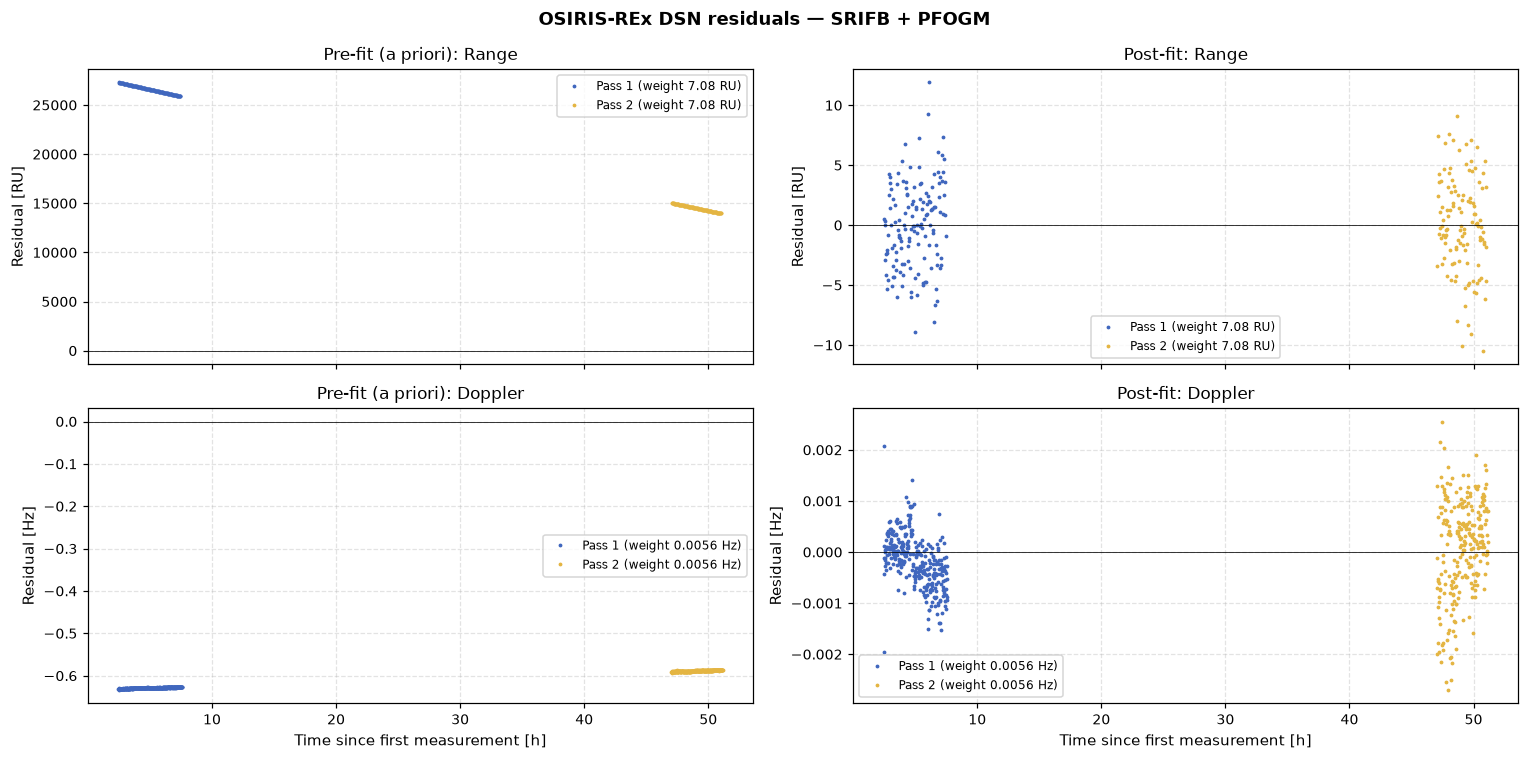

Post-fit residuals (mean / RMS, in units of the data weight):
  Range 1 DSS-35     n =  145  mean  -0.00  RMS  0.51
  Doppler 1 DSS-35   n =  307  mean  -0.03  RMS  0.10
  Range 2 DSS-35     n =  116  mean  +0.00  RMS  0.56
  Doppler 2 DSS-35   n =  247  mean  +0.01  RMS  0.17


In [8]:
palette = scb.Plotting.color_palettes["scb_palette"]
pass_colors = dict(zip(range(1, len(pass_files) + 1), [palette[0], palette[2], palette[1]]))
band_units = {"range": "RU", "doppler": "Hz"}

# Prefits of the first iteration (against the a priori) and final postfits
first_iteration = filter_od._solution_history[0]
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
fig.suptitle("OSIRIS-REx DSN residuals — SRIFB + PFOGM", fontweight="bold")
for col, (res, eps, label) in enumerate([
    (first_iteration.prefits, first_iteration.prefit_epochs, "Pre-fit (a priori)"),
    (solution.postfits, solution.postfit_epochs, "Post-fit"),
]):
    for row, band in enumerate(["range", "doppler"]):
        ax = axes[row, col]
        for name, (GS_name, ds_band, k) in dataset_info.items():
            if ds_band != band or not res.get(name):
                continue
            r = np.array(res[name], dtype=float).reshape(-1, 2)
            t_h = (np.asarray(eps[name], dtype=float) - et_min_obs) / 3600.0
            # The data weight goes in the legend: +/-3-sigma lines would
            # flatten the post-fits, which sit well inside them
            ax.plot(t_h, r[:, 0], ".", ms=3, color=pass_colors[k],
                    label=f"Pass {k} (weight {r[:, 1].max():.3g} {band_units[band]})")
        ax.axhline(0, color="k", lw=0.5)
        ax.set_title(f"{label}: {band.capitalize()}")
        ax.set_ylabel(f"Residual [{band_units[band]}]")
        ax.legend(loc="best", fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Time since first measurement [h]")
plt.tight_layout()
plt.show()

print("Post-fit residuals (mean / RMS, in units of the data weight):")
for name in filter_od.measurement_data.dataset_names:
    r = np.array(solution.postfits[name], dtype=float).reshape(-1, 2)
    print(f"  {name:<18} n = {len(r):4d}  mean {np.mean(r[:, 0] / r[:, 1]):+6.2f}  "
          f"RMS {np.sqrt(np.mean((r[:, 0] / r[:, 1]) ** 2)):5.2f}")

### Comparison with OD044
The estimate and its covariance are mapped to the measurement epochs and differenced against OD044.  Cartesian components hide the geometry, so the differences are expressed in the **RTN frame of the OD044 orbit relative to Earth**, built from the spacecraft position $\mathbf{r}$ and velocity $\mathbf{v}$ with respect to Earth (`scb.DynamicalUtils.rtn`):

- **R** — $\hat{e}_R = \mathbf{r}/\lVert\mathbf{r}\rVert$, along the Earth–spacecraft direction: the line of sight that range and Doppler measure;
- **N** — $\hat{e}_N \propto \mathbf{r} \times \mathbf{v}$, normal to the Earth-relative motion;
- **T** — $\hat{e}_T = \hat{e}_N \times \hat{e}_R$, completing the triad.

T and N are both perpendicular to the line of sight, so they span the plane of sky.

On a 53-hour arc at 0.48 AU, radiometric data pin down the line of sight to metres, while the plane-of-sky position is constrained only through the dynamics and the diurnal Doppler signature of the station's rotation.  The expected picture is therefore metre-level R errors and kilometre-level T and N errors, each inside its own covariance.

- The **R position** difference, about 2.3 m RMS against a 1.9 m sigma (1.2σ), is the 2.4–2.6 m offset of the modelled delays against OD044 (Sections 4 and 6): the line-of-sight agreement is only as good as the transponder delay calibration, here well inside its ±4 m systematics.
- The **T and N positions** differ by 7.4 and 9.5 km RMS, against sigmas of 7.6 and 4.8 km: N sits at 2σ.
- The **R velocity** sigma (about 0.34 mm/s) is larger than the 0.1 mm/s Doppler weight because a plane-of-sky position error tilts the line of sight, and the velocity along a fixed R axis must compensate to reproduce the observed range rate.
- The **T and N velocities** are not determined on this arc: their sigmas stay at the 1 cm/s a priori, and the differences of about 1.9 mm/s (T) and 4.2 mm/s (N) are what remains of the a priori velocity error.

A single number summarizes the 3-D position consistency: the **Mahalanobis distance** $\chi^2 = \delta\mathbf{r}^\top P_{rr}^{-1}\,\delta\mathbf{r}$, which follows a $\chi^2$ distribution with 3 degrees of freedom if the error is consistent with the covariance (mean 3, 95 % below 7.81).  Over the arc it has a mean of 6.0 and a maximum of 7.6, below the 95 % bound: the N error at 2σ and the R offset at 1.2σ both add to it.

Estimate - OD044 over the fit arc (RMS / mean 1-sigma):
  R     position      2.3 m  /     1.9 m   velocity  0.334 /  0.338 mm/s
  T     position   7364.7 m  /  7577.8 m   velocity  1.875 /  9.828 mm/s
  N     position   9523.1 m  /  4802.1 m   velocity  4.203 /  9.897 mm/s
Position chi^2: mean 6.04, max 7.63 (95 % bound 7.81)


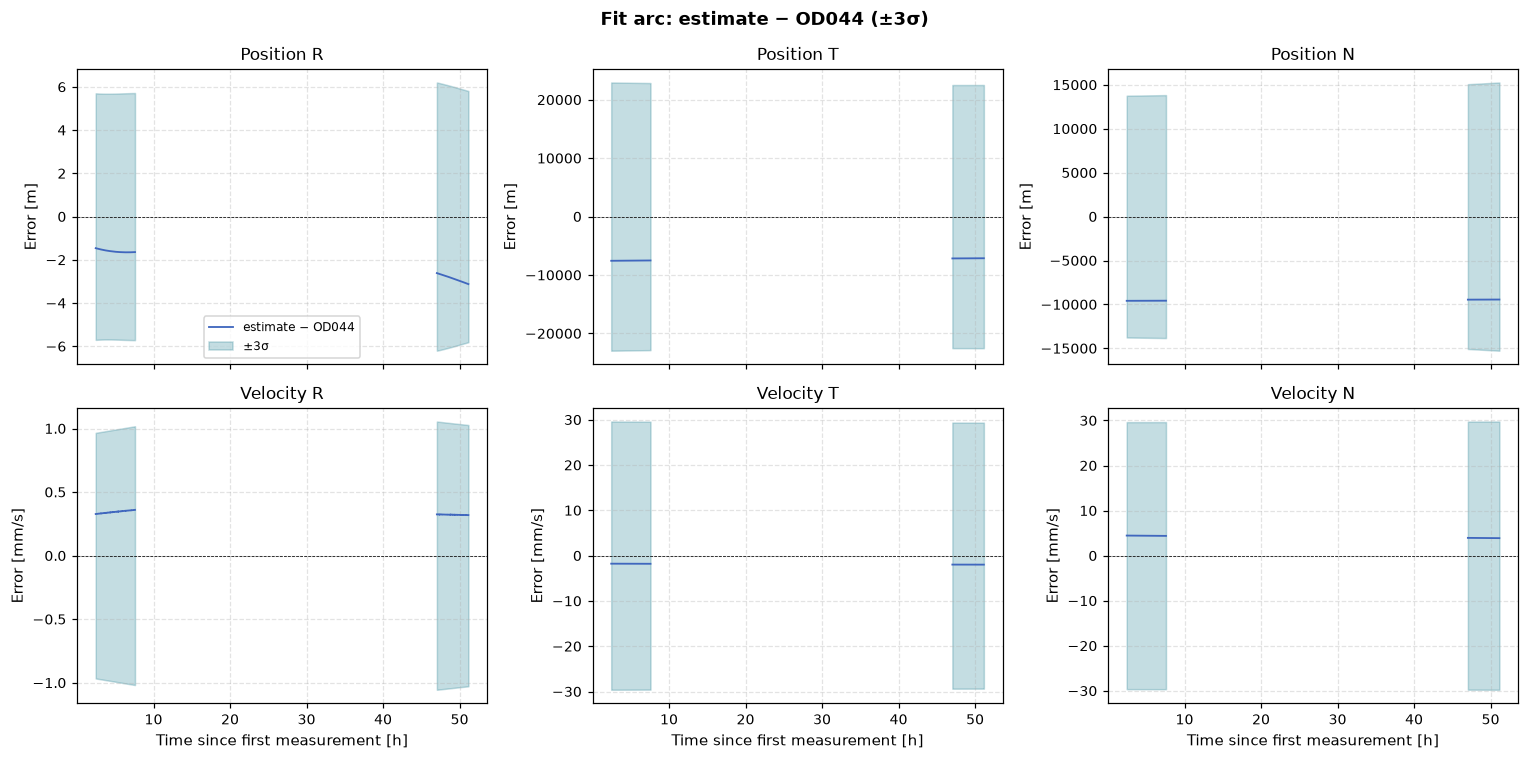

In [9]:
def rtn_axes(t):
    """OD044 states and the RTN axes (rows) of the Earth-relative OD044 orbit at epochs t."""
    od044 = np.array([scb.SpiceManager.get_state(str(sc_id), et, J2000, origin).values for et in t])
    earth = np.array([scb.SpiceManager.get_state("399", et, J2000, origin).values for et in t])
    axes = np.array([scb.DynamicalUtils.rtn(s[0:3], s[3:6])[0].T for s in od044 - earth])
    return od044, axes


def compare_od044(sol, t):
    """Estimate - OD044 in Earth RTN, with 1-sigma and the position chi^2, at epochs t."""
    pairs = sol.propagate_state_covariance(scb.EpochArray(t, sys="TDB"), use_smoothed=False, use_all_data=True)
    X = np.array([np.asarray(s.values0.values, dtype=float).ravel()[:6] for s, _ in pairs])
    P = np.array([C[:6, :6] for _, C in pairs])
    od044, A = rtn_axes(t)
    dr, dv = X[:, :3] - od044[:, :3], X[:, 3:6] - od044[:, 3:6]
    err_r = np.einsum("nij,nj->ni", A, dr)
    err_v = np.einsum("nij,nj->ni", A, dv)
    sig_r = np.sqrt(np.array([np.diag(a @ p[:3, :3] @ a.T) for a, p in zip(A, P)]))
    sig_v = np.sqrt(np.array([np.diag(a @ p[3:, 3:] @ a.T) for a, p in zip(A, P)]))
    chi2 = np.array([d @ np.linalg.solve(p[:3, :3], d) for d, p in zip(dr, P)])
    return err_r, err_v, sig_r, sig_v, chi2


fit_r, fit_v, fit_sr, fit_sv, fit_chi2 = compare_od044(solution, solution.timestamps)
print("Estimate - OD044 over the fit arc (RMS / mean 1-sigma):")
for j, comp in enumerate(["R", "T", "N"]):
    print(f"  {comp:<5} position {np.sqrt(np.mean(fit_r[:, j]**2)) * 1e3:8.1f} m  / {np.mean(fit_sr[:, j]) * 1e3:7.1f} m   "
          f"velocity {np.sqrt(np.mean(fit_v[:, j]**2)) * 1e6:6.3f} / {np.mean(fit_sv[:, j]) * 1e6:6.3f} mm/s")
print(f"Position chi^2: mean {fit_chi2.mean():.2f}, max {fit_chi2.max():.2f} (95 % bound 7.81)")

# One segment per pass, so the band is not drawn across the gaps
t_h = (solution.timestamps - et_min_obs) / 3600.0
segments = np.split(np.arange(len(t_h)), np.nonzero(np.diff(t_h) > 0.5)[0] + 1)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
fig.suptitle("Fit arc: estimate − OD044 (±3σ)", fontweight="bold")
for j, comp in enumerate(["R", "T", "N"]):
    for row, (err, sig, scale, unit) in enumerate([
        (fit_r[:, j], fit_sr[:, j], 1e3, "m"),
        (fit_v[:, j], fit_sv[:, j], 1e6, "mm/s"),
    ]):
        ax = axes[row, j]
        for i, seg in enumerate(segments):
            ax.plot(t_h[seg], err[seg] * scale, color=palette[0], lw=1.2, label="estimate − OD044" if i == 0 else None)
            ax.fill_between(t_h[seg], -3 * sig[seg] * scale, 3 * sig[seg] * scale, color=palette[1], alpha=0.25,
                            label="±3σ" if i == 0 else None)
        ax.axhline(0, color="k", lw=0.5, ls="--")
        ax.set_title(f"{'Position' if row == 0 else 'Velocity'} {comp}")
        ax.set_ylabel(f"Error [{unit}]")
axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Time since first measurement [h]")
plt.tight_layout()
plt.show()

## 7. Stochastic Accelerations

`scb.Plotting.plot_fogm_parameters_estimate()` plots the PFOGM acceleration of the **active batch** at each measurement epoch with its ±3σ band.  It reads the filter covariance by epoch index, so it must be given the measurement epochs (`solution.timestamps`).

The second figure shows every batch, including the ones after the last measurement: the batch accelerations are constant until their batch starts, so the state at the initial epoch holds the starting value of every batch.  Two things to read from it:

- **The estimated accelerations are small against their sigmas.**  The two batches of the fit arc are pulled to at most 1.7 nm/s², with sigmas of 84–95 % of the a priori: two passes of 5–8 hours from 0.48 AU cannot resolve 27-hour accelerations of this size component by component.  That is expected, and it is why their strength cannot be tuned from the post-fit residuals (Section 10).
- **The prediction batches keep their a priori sigma.**  No data constrain them, so they carry the full assumed force-model uncertainty into the prediction of Section 8.

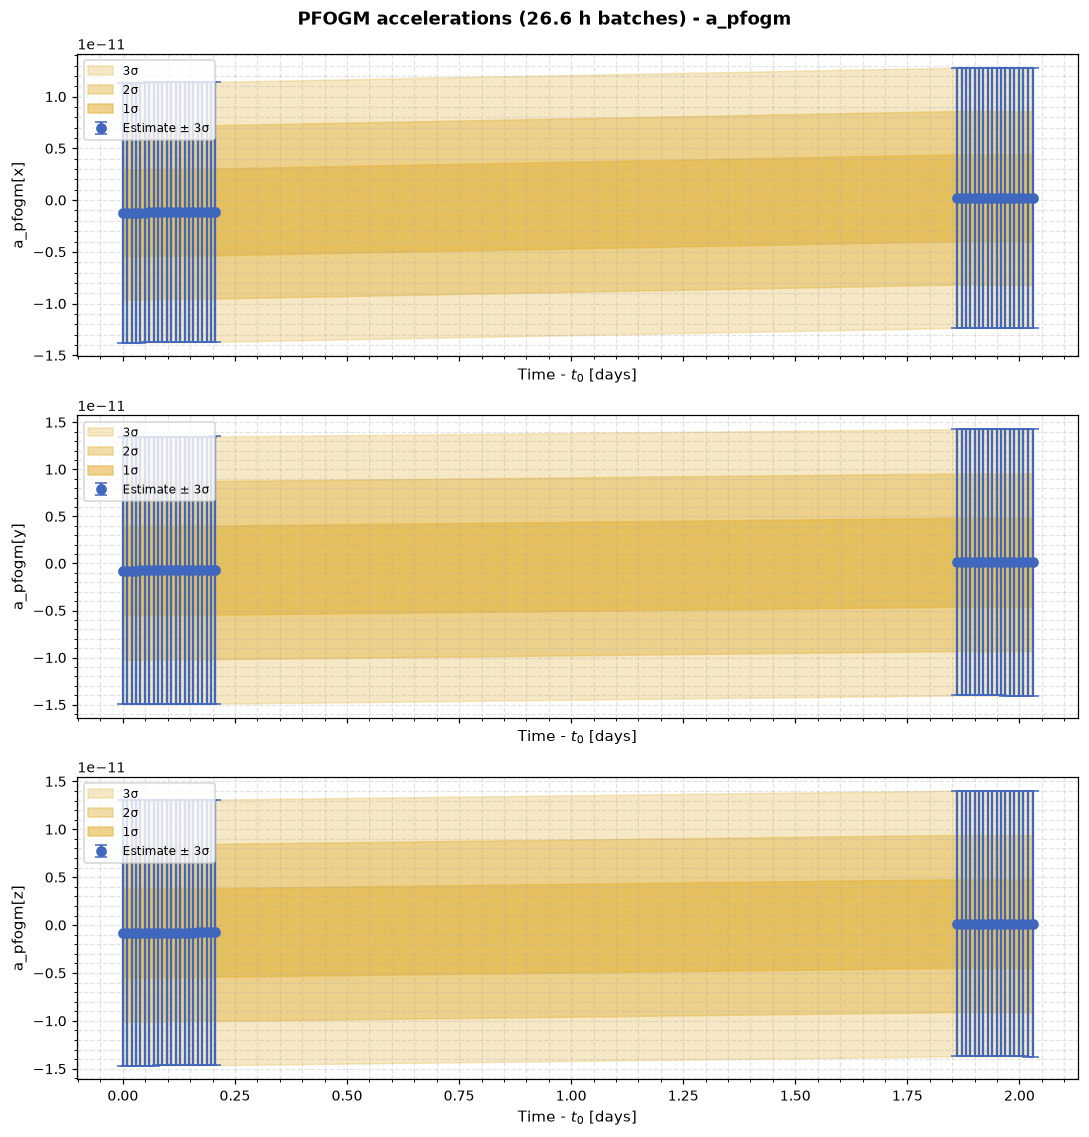

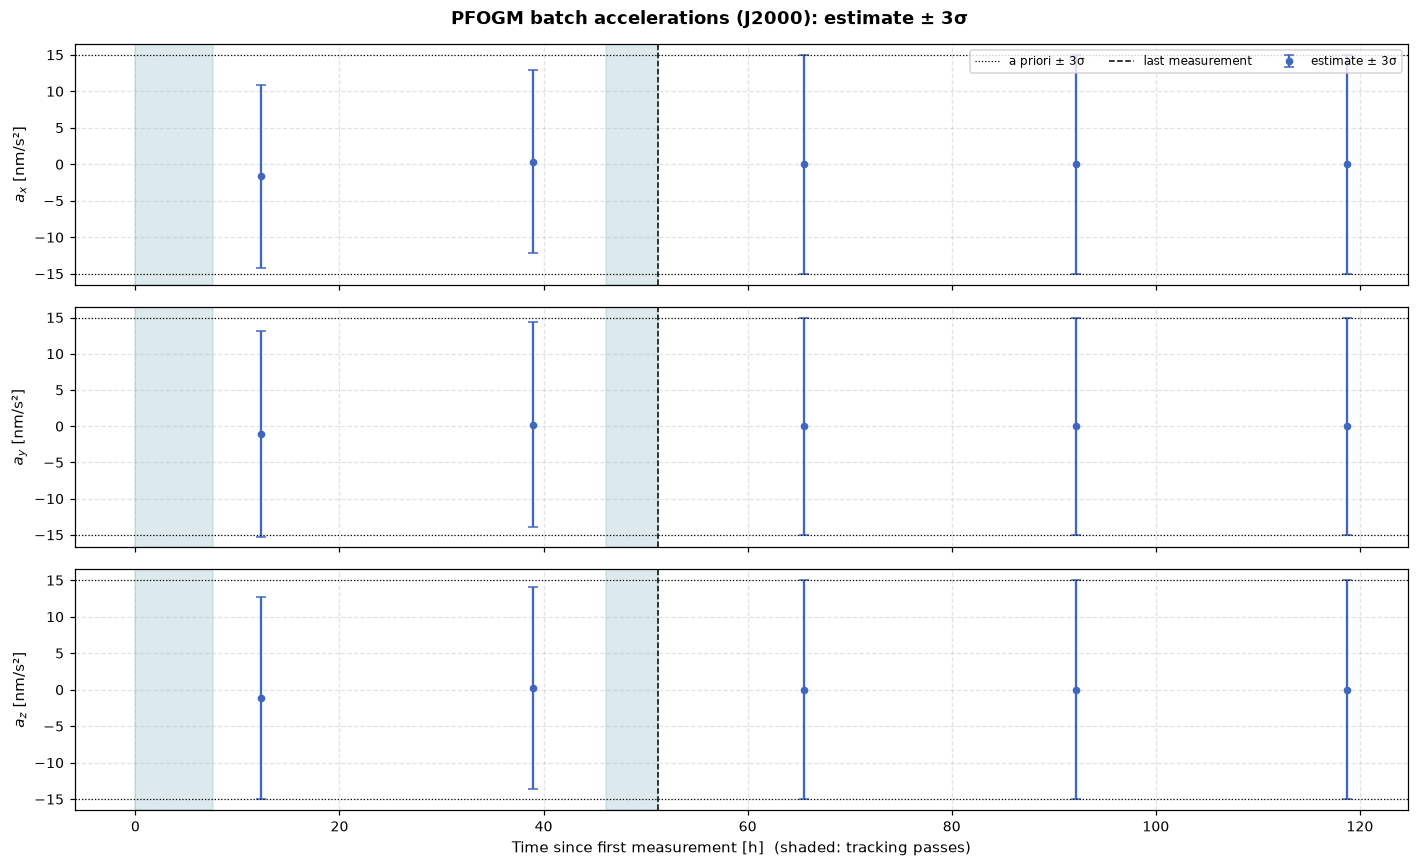

Batches in the fit arc: sigma / a priori = 0.84 - 0.95, largest |estimate| = 1.7 nm/s^2
Prediction batches: sigma / a priori = 1.00 - 1.00


In [10]:
meas_epochs = scb.EpochArray(solution.timestamps, sys="TDB")
scb.Plotting.get_fig_handle(
    scb.Plotting.plot_fogm_parameters_estimate(
        solution, meas_epochs, 3,
        title=f"PFOGM accelerations ({pfogm_batch_length / 3600:.1f} h batches)",
        use_smoothed=False,
    )
)
plt.show()

# Every batch: starting values from the state at the initial epoch
t_0 = scb.EpochArray([et_padded[0]], sys="TDB")
state_0, P_0 = solution.propagate_state_covariance(t_0, use_smoothed=False, use_all_data=True)[0]
ia = cols["a_pfogm"]
a_hat = np.asarray(state_0.values0.values, dtype=float).ravel()[ia].reshape(-1, 3)
a_sig = np.sqrt(np.diag(P_0)[ia]).reshape(-1, 3)
batch_start_h = (et_padded[0] + pfogm_batch_length * np.arange(pfogm_n_batches) - et_min_obs) / 3600.0
batch_mid_h = batch_start_h + pfogm_batch_length / 7200.0
data_end_h = (et_max_obs - et_min_obs) / 3600.0

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
fig.suptitle("PFOGM batch accelerations (J2000): estimate ± 3σ", fontweight="bold")
nm = 1e12   # km/s^2 -> nm/s^2
for j, (ax, comp) in enumerate(zip(axes, "xyz")):
    for t_a, t_b in pass_spans:
        ax.axvspan((t_a - et_min_obs) / 3600, (t_b - et_min_obs) / 3600, color=palette[1], alpha=0.15)
    ax.errorbar(batch_mid_h, a_hat[:, j] * nm, yerr=3 * a_sig[:, j] * nm, fmt="o", ms=4,
                color=palette[0], capsize=3, label="estimate ± 3σ")
    ax.axhline(3 * pfogm_sigma * nm, color="k", lw=0.8, ls=":", label="a priori ± 3σ")
    ax.axhline(-3 * pfogm_sigma * nm, color="k", lw=0.8, ls=":")
    ax.axvline(data_end_h, color="k", lw=1.0, ls="--", label="last measurement")
    ax.set_ylabel(f"$a_{comp}$ [nm/s²]")
axes[0].legend(loc="upper right", fontsize=8, ncol=3)
axes[-1].set_xlabel("Time since first measurement [h]  (shaded: tracking passes)")
plt.tight_layout()
plt.show()

with_data = batch_start_h < data_end_h
print(f"Batches in the fit arc: sigma / a priori = {np.min(a_sig[with_data] / pfogm_sigma):.2f} - "
      f"{np.max(a_sig[with_data] / pfogm_sigma):.2f}, "
      f"largest |estimate| = {np.max(np.abs(a_hat[with_data])) * nm:.1f} nm/s^2")
print(f"Prediction batches: sigma / a priori = {np.min(a_sig[~with_data] / pfogm_sigma):.2f} - "
      f"{np.max(a_sig[~with_data] / pfogm_sigma):.2f}")

## 8. Forward-Prediction Consistency Test

Post-fit residuals only show that the filter can explain the data it was given.  The test that matters for navigation is whether the **predicted** trajectory stays inside its **predicted covariance**.  The solution and its covariance are mapped from the last measurement to three days later, hourly, with `solution.propagate_state_covariance(..., use_all_data=True)`, which re-integrates the trajectory and the state transition matrix beyond the fit arc, and differenced against OD044.

Two diagnostics:
- **Error against its 3σ envelope**, per R/T/N component.  The envelope grows with time as the PFOGM sigmas of the prediction batches and the uncertainty of `eta_srp` map into position.  In the plane of sky (T and N), error and sigma are both dominated by the a priori error that the 53-hour arc cannot remove (Section 6); the PFOGM σ mainly sets how fast the R envelope grows.
- **Normalized errors and $\chi^2$.**  $e/\sigma$ per component should stay mostly within ±3, and the 3-D position $\chi^2$ below the 7.81 (95 %) and 14.16 (99.73 %) bounds of a $\chi^2$ with 3 degrees of freedom.  A $\chi^2$ that keeps growing means the covariance is **optimistic**; values persistently far below 3 mean it is **pessimistic**.

OD044 is a reconstruction, not truth, but it was built with tracking data beyond this arc, so it is a fair reference for a three-day prediction at the metre level.

On this arc the prediction $\chi^2$ starts at 7.55, its end-of-fit value, and falls to 2.0 at +72 h (mean 3.2) as the covariance grows: it stays below the 95 % bound throughout.  The R error grows from −3 m to −37 m at +72 h against a 156 m sigma, while T and N barely change from their end-of-arc values (T within 1σ, N within 1.9σ).

 time   |      R pos err / 1-sigma [m]      |     T / N err [km] (1-sigma)      |  chi^2
+  0 h  |      -3.1 /     1.9                 |   -7.13 (7.51) /  -9.44 (5.09)         |   7.55
+  6 h  |      -4.0 /     2.1                 |   -7.09 (7.51) /  -9.42 (5.19)         |   6.57
+ 12 h  |      -5.0 /     5.1                 |   -7.04 (7.53) /  -9.41 (5.30)         |   3.82
+ 24 h  |      -9.9 /    20.7                 |   -6.90 (7.57) /  -9.39 (5.54)         |   3.04
+ 48 h  |     -21.0 /    75.9                 |   -6.65 (7.71) /  -9.33 (6.08)         |   2.41
+ 72 h  |     -36.6 /   155.9                 |   -6.40 (7.94) /  -9.27 (6.70)         |   1.96

chi^2 over the prediction: mean 3.22, max 7.55, 100% below 7.81


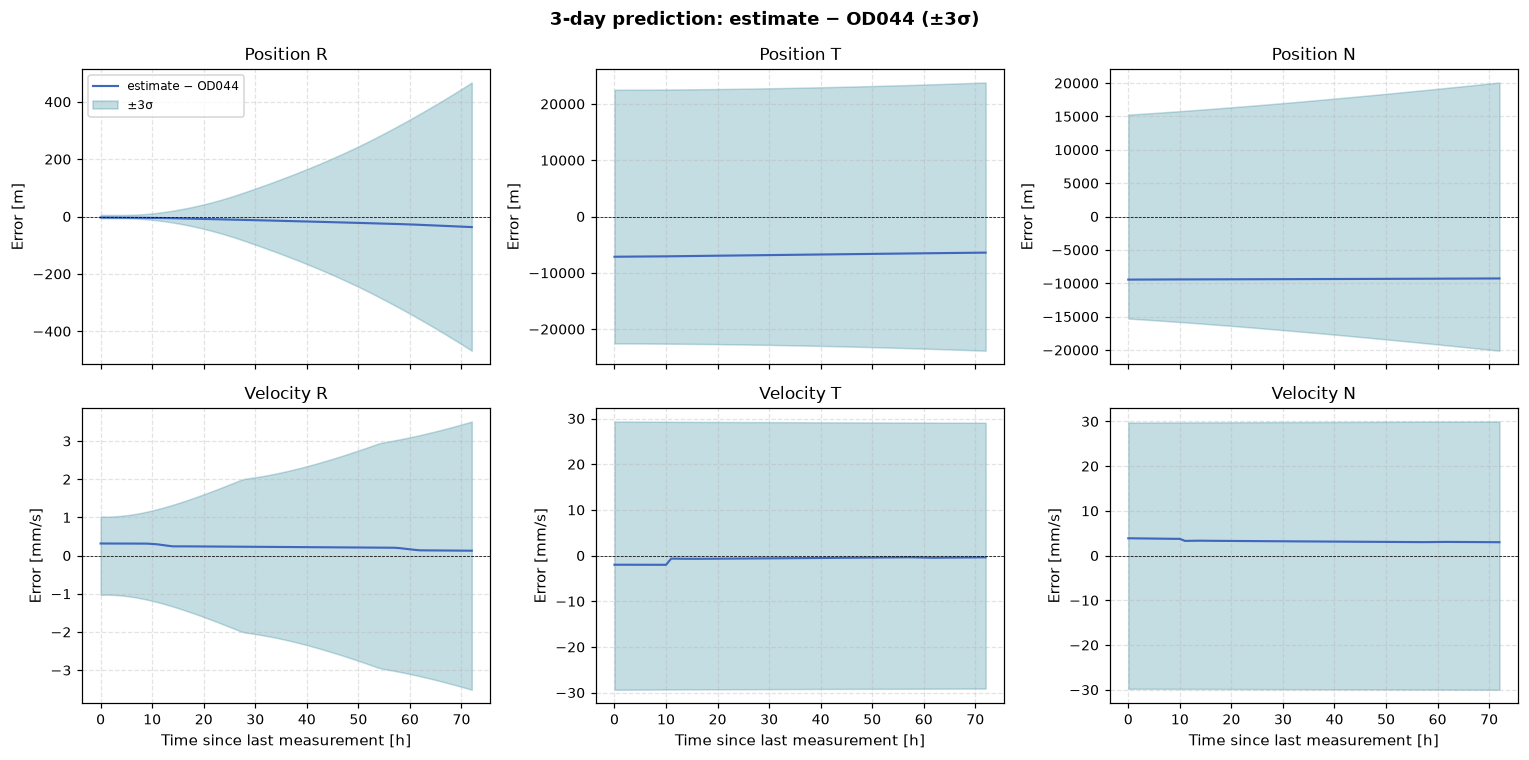

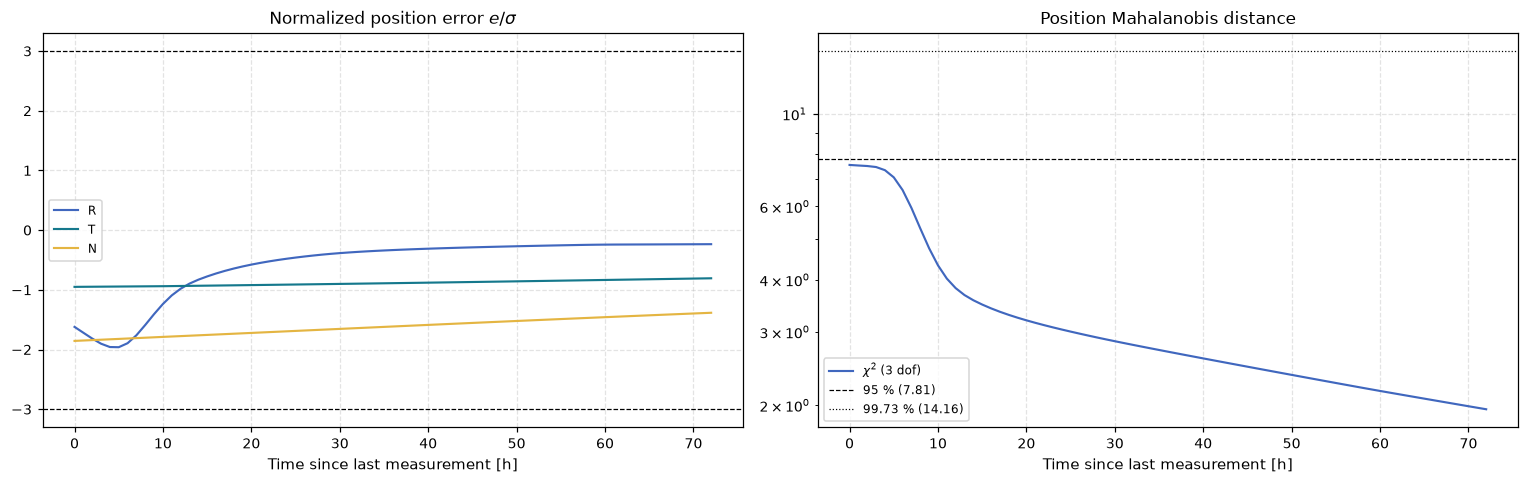

In [11]:
t_pred = et_max_obs + np.arange(0.0, pred_span + 1.0, 3600.0)
pr_r, pr_v, pr_sr, pr_sv, pr_chi2 = compare_od044(solution, t_pred)
pred_h = (t_pred - et_max_obs) / 3600.0

print(" time   |      R pos err / 1-sigma [m]      |     T / N err [km] (1-sigma)      |  chi^2")
for i in [0, 6, 12, 24, 48, 72]:
    print(f"+{i:3d} h  |  {pr_r[i, 0] * 1e3:8.1f} / {pr_sr[i, 0] * 1e3:7.1f}"
          f"                 |  {pr_r[i, 1]:6.2f} ({pr_sr[i, 1]:.2f}) / {pr_r[i, 2]:6.2f} ({pr_sr[i, 2]:.2f})"
          f"         |  {pr_chi2[i]:5.2f}")
print(f"\nchi^2 over the prediction: mean {pr_chi2.mean():.2f}, max {pr_chi2.max():.2f}, "
      f"{np.mean(pr_chi2 < 7.81):.0%} below 7.81")

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
fig.suptitle("3-day prediction: estimate − OD044 (±3σ)", fontweight="bold")
for j, comp in enumerate(["R", "T", "N"]):
    for row, (err, sig, scale, unit) in enumerate([
        (pr_r[:, j], pr_sr[:, j], 1e3, "m"),
        (pr_v[:, j], pr_sv[:, j], 1e6, "mm/s"),
    ]):
        ax = axes[row, j]
        ax.plot(pred_h, err * scale, color=palette[0], lw=1.4, label="estimate − OD044")
        ax.fill_between(pred_h, -3 * sig * scale, 3 * sig * scale, color=palette[1], alpha=0.25, label="±3σ")
        ax.axhline(0, color="k", lw=0.5, ls="--")
        ax.set_title(f"{'Position' if row == 0 else 'Velocity'} {comp}")
        ax.set_ylabel(f"Error [{unit}]")
axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Time since last measurement [h]")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for j, comp in enumerate(["R", "T", "N"]):
    axes[0].plot(pred_h, pr_r[:, j] / pr_sr[:, j], color=palette[j], lw=1.4, label=comp)
for y in (-3, 3):
    axes[0].axhline(y, color="k", lw=0.8, ls="--")
axes[0].set_title("Normalized position error $e/\\sigma$")
axes[0].set_xlabel("Time since last measurement [h]")
axes[0].legend(fontsize=8)
axes[1].semilogy(pred_h, pr_chi2, color=palette[0], lw=1.4, label="$\\chi^2$ (3 dof)")
axes[1].axhline(7.81, color="k", lw=0.8, ls="--", label="95 % (7.81)")
axes[1].axhline(14.16, color="k", lw=0.8, ls=":", label="99.73 % (14.16)")
axes[1].set_title("Position Mahalanobis distance")
axes[1].set_xlabel("Time since last measurement [h]")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Prediction Test on a Third Pass

Section 8 compares the prediction with OD044, which is itself an estimate.  A third DSS-35 pass, on 2018 July 6 (DoY 187, 05:05–09:35 UTC), tests it against the measurements themselves.  The pass starts about 45 hours after the last measurement of the fit and is **not** used in it: the question is whether the measurements predicted by the solution match the observed ones within the predicted uncertainty, i.e. whether the **pre-fit residuals** of the new pass are good, as a navigation team checks before it processes a new pass.

The test takes four steps:

1. **Predicted trajectory.**  The estimated state at the start of the window (position, velocity, every PFOGM batch and `eta_srp`, Section 7) is propagated with the same force model to the end of pass 3 and written to an SPK.  A separate `Spacecraft` (`Orbiter_pred`, SPICE ID `-1002`), with its SPK in its own folder, keeps this trajectory from shadowing OD044 or the reference trajectory of the fit.
2. **Measurement models.**  Pass 3 gets its own ranging and Doppler models and media corrections, built as in Section 2, in a separate `MeasurementSpec`.  Its range bias is not estimated, so the ranging model applies the delays of Section 2, station and transponder, and the 0 RU a priori bias of the fitted passes (`meas_bias`).
3. **Residuals.**  The pass is computed against OD044 and edited with the Huber + MAD filter of Section 4, then computed against the prediction; only the points kept by the editing are used.  The residuals against OD044 are a baseline: they contain the data noise, the media errors and the error of the modelled delays, but no prediction error.
4. **Predicted uncertainty.**  The covariance of the solution is mapped to the epochs of pass 3 with `solution.propagate_state_covariance()` and projected on each measurement through its geometric partials.  With $\boldsymbol{\rho}$ and $\Delta\mathbf{v}$ the position and velocity of the spacecraft relative to the station, $\rho = \lVert\boldsymbol{\rho}\rVert$, $\hat{\boldsymbol{\rho}} = \boldsymbol{\rho}/\rho$ and $\dot\rho = \hat{\boldsymbol{\rho}}\cdot\Delta\mathbf{v}$:

$$\frac{\partial \rho}{\partial \mathbf{r}} = \hat{\boldsymbol{\rho}}^\top, \qquad
\frac{\partial \dot\rho}{\partial \mathbf{r}} = \frac{(\Delta\mathbf{v} - \dot\rho\,\hat{\boldsymbol{\rho}})^\top}{\rho}, \qquad
\frac{\partial \dot\rho}{\partial \mathbf{v}} = \hat{\boldsymbol{\rho}}^\top,$$

scaled to RU (one RU of round-trip ranging per `RU` metres of one-way range, Section 2) and to Hz ($2 M_2 f_{ul}/c$ per unit of range rate, with the turnaround ratio $M_2 = 880/749$).  The predicted variance of a residual adds the data weight of Section 4 and, for ranging, the 2 m uncertainty of the bias of the new pass:

$$\sigma^2_{\text{pred}} = \mathbf{h}\,P_{6\times6}\,\mathbf{h}^\top + \sigma^2_{\text{bias}} + \sigma^2_{\text{weight}}.$$

The prediction passes the test if its residuals stay inside $\pm 3\sigma_{\text{pred}}$ and their RMS normalized by $\sigma_{\text{pred}}$ is about 1 or below.

  6 observation(s) in '2W_sranging' carry the -1 no-data sentinel and were flagged as outliers (indices [0, 1, 2, 3, 4, 86])
Pass 3: DSS-35, 2018-07-06T05:12 - 09:23 UTC, 45.7 h after the last fitted measurement


Predicted SPK vs mapped solution: largest position difference 0.367 m



Against OD044, after editing
Range 3 DSS-35: 90 obs, 6 flagged, residual RMS (kept) = 1.740540e+01 vs Orbiter[-64] via orx_180301_181201_180921_od044_v1.bsp
Doppler 3 DSS-35: 200 obs, 19 flagged, residual RMS (kept) = 1.565137e-03 vs Orbiter[-64] via orx_180301_181201_180921_od044_v1.bsp



Against the prediction
Range 3 DSS-35: 90 obs, 6 flagged, residual RMS (kept) = 1.373946e+02 vs orbiter_pred[-1002] via orex_pass3_prediction.bsp
Doppler 3 DSS-35: 200 obs, 19 flagged, residual RMS (kept) = 6.500868e-03 vs orbiter_pred[-1002] via orex_pass3_prediction.bsp

dataset             n      mean       RMS  mean sigma  RMS/sigma in 3 sigma   RMS vs OD044
Range 3 DSS-35     84   +19.408    19.419      76.940       0.25       100%       2.460 m
Doppler 3 DSS-35  181    +6.274     6.501      46.680       0.14       100%       1.565 mHz


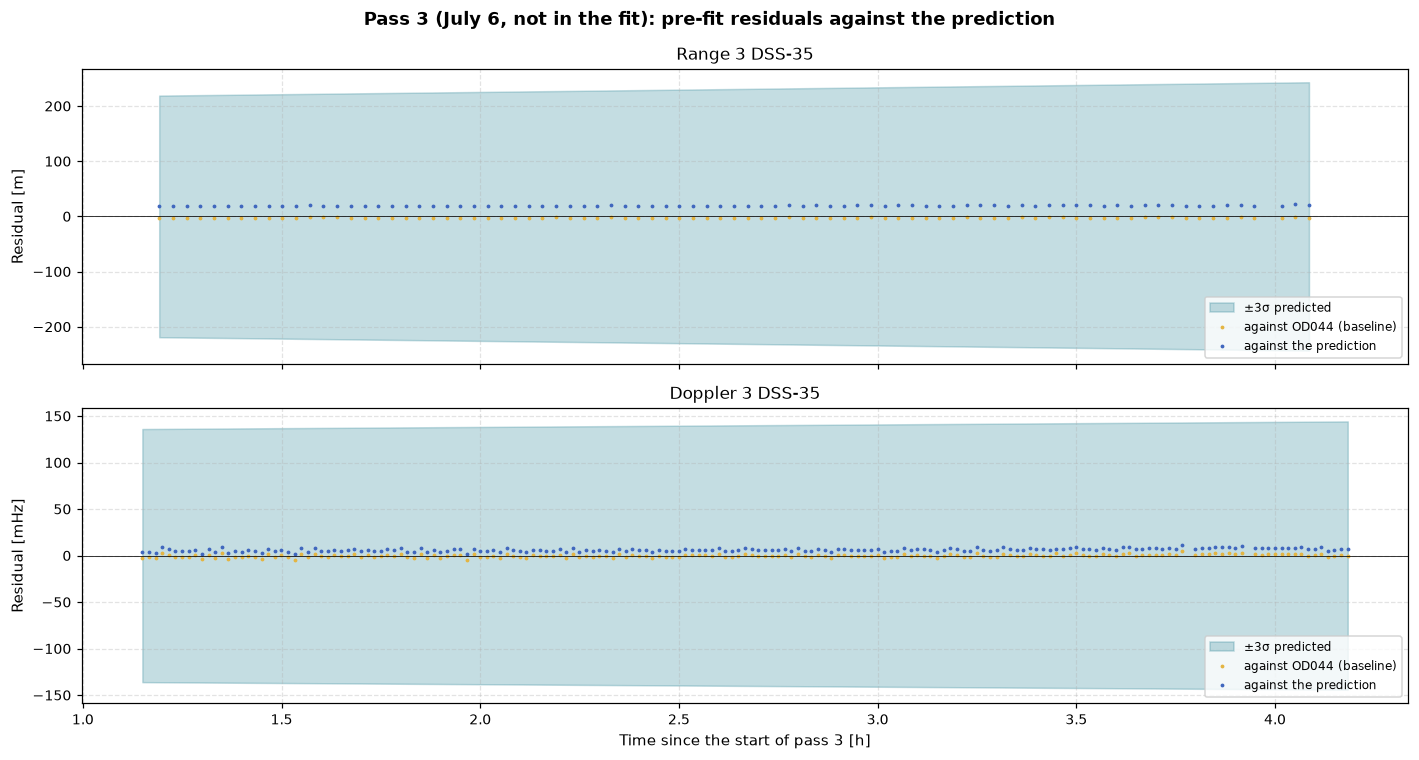

In [12]:
@contextlib.contextmanager
def quiet():
    """Silence the output and warnings of a computation (also used by the repeated fits of Section 10)."""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()), \
            warnings.catch_warnings():
        warnings.simplefilter("ignore")
        yield


# Pass 3: same station, models built as in Section 2, never handed to the filter
trk_file_3 = data.trk_file_187_dss35.path
GS = stations["DSS-35"]
# Its bias is not estimated: the ranging model applies the delays of Section 2
# and the a priori bias of the fitted passes
range_3 = scb.SequentialRangingReal("Range 3 DSS-35", GS, sigma=sranging_sigma, electronic_delays=True,
                                    meas_bias=filter_bias_apriori)
doppler_3 = scb.DopplerReal("Doppler 3 DSS-35", GS, sigma=doppler_sigma, electronic_delays=True)
sr_obs_3 = range_3.observed_measurements(trk_file_3, meas_name="2W_sranging", units=km / km,
                                         sc_transponder_delay_RU=scft_transpd_delay)
doppler_obs_3 = doppler_3.observed_measurements(trk_file_3, meas_name="2W_doppler", units=1 / sec,
                                                sc_transponder_delay_RU=scft_transpd_delay)
range_3 = add_media_corrections(sr_obs_3, range_3, GS, "Media range 3")
doppler_3 = add_media_corrections(doppler_obs_3, doppler_3, GS, "Media Doppler 3")
pass3 = scb.MeasurementSpec.many(
    scb.MeasurementSpec(model=range_3, observed_meas=sr_obs_3, dataset_name=range_3.name,
                        file_label="real_range_3"),
    scb.MeasurementSpec(model=doppler_3, observed_meas=doppler_obs_3, dataset_name=doppler_3.name,
                        file_label="real_range_rate_3"),
)
RU_s_3 = 1.0 / (np.unique(sr_obs_3.aux_dict["RU"])[0] * np.unique(sr_obs_3.aux_dict["ul_freq"])[-1])
RU_m_3 = RU_s_3 * float(scb.constants.c.values) * scb.constants.km_to_m / 2
t3_obs = np.unique(np.concatenate([sr_obs_3.meas_time_et.times.values, doppler_obs_3.meas_time_et.times.values]))
print(f"Pass 3: DSS-35, {scb.SpiceManager.et2utc(t3_obs[0])[:16]} - {scb.SpiceManager.et2utc(t3_obs[-1])[11:16]} UTC, "
      f"{(t3_obs[0] - et_max_obs) / 3600:.1f} h after the last fitted measurement")

# 1. Predicted trajectory: the estimate at the start of the window (Section 7),
#    propagated to the end of pass 3 under its own SPICE ID and SPK folder
x_0 = np.asarray(state_0.values0.values, dtype=float).ravel()
Orbiter_pred = scb.Spacecraft("orbiter_pred", -1002, Orbiter_mass, Orbiter_area, Orbiter_cr_srp)
pred_epochs = scb.EpochArray(np.arange(et_padded[0], t3_obs[-1] + 3600.0, 60.0), sys="TDB")
state_pred = scb.StateArray(epoch=pred_epochs[0], origin=origin, state=scb.StateDefinition.from_components(
    dynamical_components(Orbiter_pred, x_0[cols["position"]], x_0[cols["velocity"]],
                         x_0[cols["a_pfogm"]], float(x_0[cols["eta_srp"][0]]))))
prop_pred = scb.Propagator(primary_body=Orbiter_pred, state_vector=state_pred, tspan=pred_epochs,
                           force_models=force_model(Orbiter_pred), propagate_STM=False, display_progress=False)
with quiet():
    prop_pred.propagate()
pred_dir = tut_kernels_path / "pass3_prediction"
pred_dir.mkdir(exist_ok=True)
scb.Trajectory("orex_pass3_prediction", state_array=prop_pred.propagated_state_array).write_to_spk(
    str(pred_dir / "orex_pass3_prediction.bsp"), append_if_exists=False, write_stms=False)

# Predicted state and covariance at the epochs of pass 3
pairs = solution.propagate_state_covariance(scb.EpochArray(t3_obs, sys="TDB"), use_smoothed=False, use_all_data=True)
X3 = np.array([np.asarray(s.values0.values, dtype=float).ravel()[:6] for s, _ in pairs])
P3 = np.array([C[:6, :6] for _, C in pairs])
spk3 = np.array([scb.SpiceManager.get_state(str(Orbiter_pred.spice_id), et, J2000, origin).values for et in t3_obs])
print(f"Predicted SPK vs mapped solution: largest position difference {np.abs(spk3[:, :3] - X3[:, :3]).max() * 1e3:.3f} m")

# 3. Residuals: against OD044, edited as in Section 4, then against the prediction
with quiet():
    pass3.compute(target=Orbiter, frame=frame)
    for leaf in pass3.leaves:
        pass3.edit("huber_mad_filter", dataset_name=leaf.dataset_name, n_sigma=5.0)
# Data weights as in Section 4
range_3.sigma = scb.ArrayWUnits(range_weight_m / RU_m_3, km / km)
if float(np.ravel(doppler_3.sigma.values)[0]) < float(doppler_floor.values):
    doppler_3.sigma = doppler_floor
print("\nAgainst OD044, after editing\n" + pass3.summary())
res_od044 = {name: r.copy() for name, r in pass3.residuals().items()}
with quiet():
    pass3.compute(target=Orbiter_pred, frame=frame)
print("\nAgainst the prediction\n" + pass3.summary())
res_pred = pass3.residuals()

# 4. Predicted sigma of each kept residual
c_kms = float(scb.constants.c.values)   # [km/s]


def predicted_sigma(leaf, kept):
    """Predicted 1-sigma of the residuals of `leaf` at its kept rows."""
    t = np.asarray(leaf.observed_meas[0].times.values, dtype=float).ravel()
    i = np.searchsorted(t3_obs, t[kept])
    earth = np.array([scb.SpiceManager.get_state("399", et, J2000, origin).values for et in t[kept]])
    station = np.array([GS.nominal_state(et, "J2000").quantity.values for et in t[kept]])
    rel = X3[i] - earth - station                  # spacecraft relative to the station
    rho = np.linalg.norm(rel[:, :3], axis=1)
    u = rel[:, :3] / rho[:, None]
    if leaf.model is range_3:
        h = np.hstack([u * 1e3 / RU_m_3, np.zeros_like(u)])                 # [RU per km]
        extra = (filter_bias_sigma_m / RU_m_3) ** 2
    else:
        aux = leaf.observed_meas.aux_dict
        f_ul = np.broadcast_to(np.asarray(aux["ul_freq"], dtype=float), t.shape)[kept]
        M2 = np.broadcast_to(np.asarray(aux["M2_num"], dtype=float) / np.asarray(aux["M2_den"], dtype=float),
                             t.shape)[kept]
        rdot = np.sum(u * rel[:, 3:], axis=1)
        h = (2 * M2 * f_ul / c_kms)[:, None] * np.hstack([(rel[:, 3:] - rdot[:, None] * u) / rho[:, None], u])
        extra = 0.0
    weight = float(np.ravel(leaf.model.sigma.values)[0])
    return np.sqrt(np.einsum("ni,nij,nj->n", h, P3[i], h) + extra + weight**2)


t3_h0 = t3_obs[0]
pass3_results = {}
print(f"\n{'dataset':<16} {'n':>4} {'mean':>9} {'RMS':>9} {'mean sigma':>11} {'RMS/sigma':>10} "
      f"{'in 3 sigma':>10}   {'RMS vs OD044':>12}")
for leaf in pass3.leaves:
    name = leaf.dataset_name
    kept = np.asarray(leaf.dataset.data["outlier_flag"]).ravel() == 0
    t = np.asarray(leaf.observed_meas[0].times.values, dtype=float).ravel()
    assert len(t) == len(kept) == len(res_pred[name]) == len(res_od044[name])
    sig = predicted_sigma(leaf, kept)
    r, r0 = res_pred[name][kept], res_od044[name][kept]
    # Ranging in one-way metres, Doppler in mHz
    scale, unit = (RU_m_3, "m") if leaf.model is range_3 else (1e3, "mHz")
    pass3_results[name] = dict(t_h=(t[kept] - t3_h0) / 3600.0, r=r * scale, r0=r0 * scale, sig=sig * scale,
                               unit=unit)
    print(f"{name:<16} {kept.sum():4d} {np.mean(r) * scale:+9.3f} {np.sqrt(np.mean(r**2)) * scale:9.3f} "
          f"{np.mean(sig) * scale:11.3f} {np.sqrt(np.mean((r / sig) ** 2)):10.2f} "
          f"{np.mean(np.abs(r) < 3 * sig):10.0%}   {np.sqrt(np.mean(r0**2)) * scale:9.3f} {unit}")

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
fig.suptitle("Pass 3 (July 6, not in the fit): pre-fit residuals against the prediction", fontweight="bold")
for ax, (name, res) in zip(axes, pass3_results.items()):
    ax.fill_between(res["t_h"], -3 * res["sig"], 3 * res["sig"], color=palette[1], alpha=0.25,
                    label="±3σ predicted")
    ax.plot(res["t_h"], res["r0"], ".", ms=3, color=palette[2], label="against OD044 (baseline)")
    ax.plot(res["t_h"], res["r"], ".", ms=3, color=palette[0], label="against the prediction")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(name)
    ax.set_ylabel(f"Residual [{res['unit']}]")
    ax.legend(loc="best", fontsize=8)
axes[-1].set_xlabel("Time since the start of pass 3 [h]")
plt.tight_layout()
plt.show()

### Result
- **Ranging.**  The observed ranges are 19.4 m longer than the predicted ones, nearly constant over the pass (RMS 19.4 m).  This is the R error of the prediction at this time in Section 8 (−21 m at +48 h; the sign flips because a residual is observed − computed), less the delay offset that pass 3 shares with the fitted passes: against OD044 its residuals are −2.4 m on average (RMS 2.5 m), as in Section 4.  The offset against the prediction therefore comes from the prediction, not from the data or the delay calibration.
- **Doppler.**  +6.3 mHz mean and 6.5 mHz RMS, about 0.11 mm/s of line-of-sight velocity, against 1.6 mHz for OD044.
- **Against the predicted uncertainty.**  Every point is inside ±3σ, and the RMS is 0.25σ for ranging and 0.14σ for Doppler: the predicted covariance is **conservative** along the line of sight.  The predicted sigmas (77 m, 47 mHz) come mostly from the PFOGM batches of the prediction, which carry their full a priori (Section 7); Section 10 shows how they change with the PFOGM σ.

A navigation team would accept this pass: its pre-fit residuals are well inside the predicted uncertainty, and its outliers are found by the same editing as in Section 4.

## 10. Dynamical Tuning of the PFOGM Strength

The PFOGM σ is a statement about how wrong the force model is, and it cannot be read off the post-fit residuals: the data weights are conservative and the stochastic accelerations are barely observable on this arc (Section 7), so J/n hardly moves when σ changes.  What σ does change is the **predicted covariance**.  The tuning therefore repeats the fit and the forward-prediction test for a range of σ and compares, for each, the prediction $\chi^2$ with its expected value of 3 and the line-of-sight (R) error with its sigma:

- **σ too small** (or no PFOGM): the covariance shrinks to what a perfect force model would allow, and the prediction error leaves it ($\chi^2$ above the bounds, errors beyond their sigma) — an **over-optimistic** solution;
- **σ too large**: the covariance grows much faster than the error ($\chi^2 \ll 3$, errors far inside their sigma) — a **pessimistic** solution that wastes margin, and the SRP scale factor loses precision as the stochastic accelerations absorb its signal.

Each fit takes a few seconds; the output of the repeated fits is silenced.  The correlation time τ can be tuned the same way.

PFOGM sigma       it     J/n         eta_srp   chi2<7.81 mean chi2  max chi2      R err / 1-sigma at +72 h
no PFOGM           2  0.1036   1.282 +/- 0.060         47%      8.82     12.59           16.1 m /    9.9 m
1.0e-12 km/s²      2  0.1034   1.285 +/- 0.075        100%      2.78      6.42           17.7 m /   34.1 m
2.5e-12 km/s²      3  0.1033   1.283 +/- 0.126        100%      2.90      6.95           22.7 m /   81.1 m
5.0e-12 km/s²      3  0.1034   1.263 +/- 0.214        100%      3.22      7.55           36.6 m /  155.9 m
1.0e-11 km/s²      4  0.1041   1.198 +/- 0.339         93%      3.61      8.51           73.7 m /  285.5 m
2.0e-11 km/s²      5  0.1053   1.095 +/- 0.439         93%      3.97      9.77          131.5 m /  507.0 m


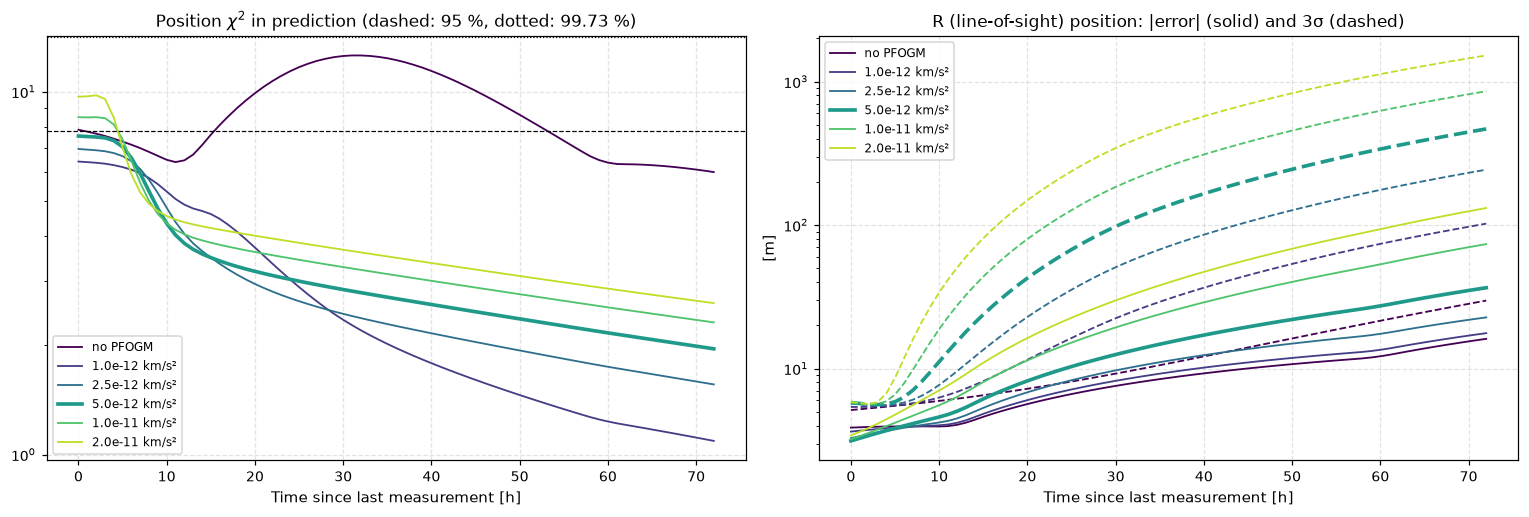

In [13]:
sweep_sigmas = [None, 1e-12, 2.5e-12, 5e-12, 1e-11, 2e-11]
sweep = {}
for i, sig in enumerate(sweep_sigmas):
    if sig == pfogm_sigma:
        # Nominal run of Sections 5-8
        j = cols["eta_srp"][0]
        sweep[sig] = dict(n_it=n_iters, J=J_all, eta=x_end[j], s_eta=np.sqrt(P_end[j, j]),
                          err=pr_r, sig=pr_sr, chi2=pr_chi2)
        continue
    with quiet():
        _, sol_i, n_it_i, _, cols_i = run_batch_od(sig, f"tune{i}", verbose=False)
        J_i = normalized_cost(sol_i)[0]
        st_i, P_i = sol_i.propagate_state_covariance(t_end, use_smoothed=False, use_all_data=True)[0]
        # Evaluated right after the fit, before the next one replaces its trajectory files
        err_i, _, sig_i, _, chi2_i = compare_od044(sol_i, t_pred)
    j = cols_i["eta_srp"][0]
    sweep[sig] = dict(n_it=n_it_i, J=J_i, eta=np.asarray(st_i.values0.values, dtype=float).ravel()[j],
                      s_eta=np.sqrt(P_i[j, j]), err=err_i, sig=sig_i, chi2=chi2_i)


def label(sig):
    return "no PFOGM" if sig is None else f"{sig:.1e} km/s²"


print(f"{'PFOGM sigma':<16} {'it':>3} {'J/n':>7} {'eta_srp':>15}   {'chi2<7.81':>9} {'mean chi2':>9} {'max chi2':>9}"
      f"   {'R err / 1-sigma at +72 h':>27}")
for sig, r in sweep.items():
    print(f"{label(sig):<16} {r['n_it']:>3} {r['J']:7.4f} {r['eta']:7.3f} +/- {r['s_eta']:.3f}"
          f"   {np.mean(r['chi2'] < 7.81):9.0%} {r['chi2'].mean():9.2f} {r['chi2'].max():9.2f}"
          f"   {abs(r['err'][-1, 0]) * 1e3:12.1f} m / {r['sig'][-1, 0] * 1e3:6.1f} m")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
colors = plt.cm.viridis(np.linspace(0.0, 0.9, len(sweep)))
for c, (sig, r) in zip(colors, sweep.items()):
    lw = 2.4 if sig == pfogm_sigma else 1.2
    axes[0].semilogy(pred_h, r["chi2"], color=c, lw=lw, label=label(sig))
    axes[1].semilogy(pred_h, np.abs(r["err"][:, 0]) * 1e3, color=c, lw=lw, label=label(sig))
    axes[1].semilogy(pred_h, 3 * r["sig"][:, 0] * 1e3, color=c, lw=lw, ls="--")
axes[0].axhline(7.81, color="k", lw=0.8, ls="--")
axes[0].axhline(14.16, color="k", lw=0.8, ls=":")
axes[0].set_title("Position $\\chi^2$ in prediction (dashed: 95 %, dotted: 99.73 %)")
axes[1].set_title("R (line-of-sight) position: |error| (solid) and 3σ (dashed)")
axes[1].set_ylabel("[m]")
for ax in axes:
    ax.set_xlabel("Time since last measurement [h]")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 11. Summary

- **Two passes, one station, real data.**  After robust editing and with operational data weights (1 m range, 0.1 mm/s Doppler), the batch SRIF converges in 3 iterations from an a priori 8 km and 12 mm/s away from OD044.
- **Delays.**  The station delays and the spacecraft transponder delay are modelled; the transponder delay, 1649.9 ns, is not public and was estimated in house from the 2017 Earth gravity assist.  Against OD044 it leaves a range offset of 2.4–2.6 m one-way, the same on all three passes and inside its ±4 m systematics.
- **Parameters.**  `eta_srp` = 1.26 ± 0.21 (effective `C_r` ≈ 1.01).  The two range biases split ±0.9 m around their 0 RU a priori: their mean is the a priori itself.
- **Agreement with OD044.**  2.3 m along the line of sight (R), the delay offset above, and 7–10 km in the plane of sky (T and N), with a position $\chi^2$ of 6.0 on average and at most 7.6, below the 95 % bound: the expected pattern for a 53-hour radiometric arc.
- **Prediction.**  Over three days the position $\chi^2$ falls from 7.55 to 2.0 (mean 3.2), below the 95 % bound; the R error grows to 37 m against a 156 m sigma.
- **Third pass.**  The pre-fit residuals of the July 6 pass, 46 hours after the fit, are +19 m in ranging and +6 mHz in Doppler, all inside ±3σ of the predicted uncertainty (RMS 0.25σ and 0.14σ).
- **Tuning.**  The post-fit residuals cannot choose the stochastic-acceleration strength: across the sweep J/n stays at 0.103–0.105.  The prediction test can:
  - without stochastic accelerations, $\chi^2$ is above the 95 % bound for half of the prediction (mean 8.8, max 12.6), and the +72 h R error (16 m) is 1.6 times its sigma: the covariance is optimistic;
  - σ = 1–2.5×10⁻¹² km/s² gives the smallest prediction errors (18–23 m in R at +72 h, against sigmas of 34–81 m), with a mean $\chi^2$ of 2.8–2.9, the closest to 3;
  - σ = 5×10⁻¹² km/s², the value used here, gives a mean $\chi^2$ of 3.2, but its R sigma at +72 h (156 m) is 4.3 times the error, as the third pass confirms (RMS 0.25σ);
  - 1×10⁻¹¹ and 2×10⁻¹¹ km/s² start to absorb the SRP signal: `eta_srp` drifts from 1.28 to 1.20 and 1.10 with sigmas of 0.34–0.44, the +72 h R error grows to 74–132 m, and $\chi^2$ leaves the 95 % bound for 7 % of the prediction.

  On this arc the 3-D $\chi^2$ is dominated by the plane-of-sky errors, so the line-of-sight component and the third pass are the sharper tests.  Both favour 1–2.5×10⁻¹², as does the mean $\chi^2$, and the 5×10⁻¹² used here is on the conservative side.

### Things to try
- Change the correlation time `pfogm_tau` or the batch length and repeat the tuning.
- Express the stochastic accelerations in the RTN frame of the spacecraft.
- Loosen the range-bias sigma (`filter_bias_sigma_m`) and watch the R (line-of-sight) position follow the biases.
- Turn the delays off (`electronic_delays=False` in the models of Sections 2 and 9, which also drops the transponder delay): the ranging residuals of Section 4 jump to about 2025 RU (286 m one-way), so the range biases must carry the whole delay and their a priori (`filter_bias_apriori`) sets the line-of-sight position.
- Add pass 3 to `pass_files` and fit all three passes: the T and N sigmas shrink, and the third PFOGM batch is no longer a prediction batch.